In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os
from datetime import datetime, timedelta
import seaborn as sns


In [103]:
base_path = "Meaconing/dynamic/Very High Power (≥10W)/Bands_E1_L1_L2/3.2.7"  # Update this to your actual path


In [104]:
# Function to load CSV files and display basic information
def load_and_describe_csv(file_path, file_name):
    print(f"\n=== Loading {file_name} ===")
    try:
        df = pd.read_csv(file_path)
        print(f"Successfully loaded {file_name}")
        print(f"Shape: {df.shape}")
        print(f"Columns: {df.columns.tolist()}")
        print("\nSample data (first 5 rows):")
        print(df.head())
        print("\nBasic statistics:")
        print(df.describe().transpose())
        return df
    except Exception as e:
        print(f"Error loading {file_name}: {e}")
        return None

# Function to extract attack periods from scenario JSON
def extract_attack_periods(scenario_info):
    """Extract all attack periods from scenario information."""
    attack_periods = []
    
    if 'attack_log' not in scenario_info:
        print("No attack_log found in scenario info")
        return attack_periods
        
    events = scenario_info['attack_log']
    
    # Sort events by timestamp
    events = sorted(events, key=lambda x: x['timestamp_utc'])
    
    # Find start-end pairs
    i = 0
    while i < len(events) - 1:
        if 'start' in events[i]['event'].lower() and 'end' in events[i+1]['event'].lower():
            start = datetime.fromisoformat(events[i]['timestamp_utc'].replace('Z', '+00:00'))
            end = datetime.fromisoformat(events[i+1]['timestamp_utc'].replace('Z', '+00:00'))
            attack_periods.append((start, end))
            i += 2
        else:
            i += 1
            
    return attack_periods

# Function to load JSON file
def load_scenario_json(file_path):
    print("\n=== Loading Scenario JSON ===")
    try:
        with open(file_path, 'r') as f:
            scenario_info = json.load(f)
        print("Successfully loaded scenario.json")
        print("\nScenario Information:")
        for key, value in scenario_info.items():
            if key != "attack_parameters" and key != "attack_log":
                print(f"{key}: {value}")
        
        print("\nAttack Parameters:")
        for key, value in scenario_info["attack_parameters"].items():
            print(f"{key}: {value}")
        
        print("\nAttack Log:")
        for event in scenario_info["attack_log"]:
            print(f"- {event['timestamp_utc']}: {event['event']}")
        
        return scenario_info
    except Exception as e:
        print(f"Error loading scenario.json: {e}")
        return None

# Load the data files
print("Loading GNSS jamming scenario data...")

# Load rinex data
rinex_path = os.path.join(base_path, "rinex.csv")
rinex_data = load_and_describe_csv(rinex_path, "rinex.csv")

# Load nav_pvt data
nav_pvt_path = os.path.join(base_path, "nav_pvt.csv")
nav_pvt_data = load_and_describe_csv(nav_pvt_path, "nav_pvt.csv")

# Load mon_rf data
mon_rf_path = os.path.join(base_path, "mon_rf.csv")
mon_rf_data = load_and_describe_csv(mon_rf_path, "mon_rf.csv")

# Load scenario information
scenario_path = os.path.join(base_path, "scenario.json")
scenario_info = load_scenario_json(scenario_path)

# Extract all attack periods from scenario info
if scenario_info:
    attack_periods = extract_attack_periods(scenario_info)
    
    print(f"\n=== Attack Periods ===")
    for i, (start, end) in enumerate(attack_periods):
        print(f"Attack {i+1}:")
        print(f"  Start: {start}")
        print(f"  End: {end}")
        print(f"  Duration: {end - start}")
    
    # For backward compatibility with existing code
    if attack_periods:
        attack_start = attack_periods[0][0]  # First attack start
        attack_end = attack_periods[0][1]    # First attack end
        print(f"\nUsing first attack period for compatibility: {attack_start} to {attack_end}")

# Print summary of data loading
print("\n=== Data Loading Summary ===")
print(f"Rinex data: {'Loaded successfully' if rinex_data is not None else 'Failed to load'}")
print(f"Nav_pvt data: {'Loaded successfully' if nav_pvt_data is not None else 'Failed to load'}")
print(f"Mon_rf data: {'Loaded successfully' if mon_rf_data is not None else 'Failed to load'}")
print(f"Scenario info: {'Loaded successfully' if scenario_info is not None else 'Failed to load'}")
print(f"Attack periods: {len(attack_periods) if 'attack_periods' in locals() else 0} found")

Loading GNSS jamming scenario data...

=== Loading rinex.csv ===
Successfully loaded rinex.csv
Shape: (256556, 10)
Columns: ['time', 'satellite', 'pseudorange_L1', 'carrier_phase_L1', 'doppler_L1', 'snr_L1', 'pseudorange_L2', 'carrier_phase_L2', 'doppler_L2', 'snr_L2']

Sample data (first 5 rows):
                         time satellite  pseudorange_L1  carrier_phase_L1  \
0  2024-09-10 11:55:59.595999       S23    3.922521e+07      2.061299e+08   
1  2024-09-10 11:55:59.595999       G01    2.155304e+07      1.132619e+08   
2  2024-09-10 11:55:59.595999       G04    1.987032e+07      1.044192e+08   
3  2024-09-10 11:55:59.595999       G06    2.125283e+07      1.116844e+08   
4  2024-09-10 11:55:59.595999       G07    2.292406e+07      1.204667e+08   

   doppler_L1  snr_L1  pseudorange_L2  carrier_phase_L2  doppler_L2  snr_L2  
0      37.296    40.0             NaN               NaN         NaN     NaN  
1    -128.389    44.0    2.155304e+07      8.825609e+07     -99.968    41.0  
2   

In [105]:
# Convert time column to datetime objects in rinex_data
rinex_data['time'] = pd.to_datetime(rinex_data['time'])

# Extract attack periods from scenario info
attack_periods = extract_attack_periods(scenario_info)

# Apply time adjustment to align with other data sources
time_adjustment = timedelta(hours=2, seconds=-18)
adjusted_attack_periods = []

print(f"Detected {len(attack_periods)} attack periods:")
for i, (start, end) in enumerate(attack_periods):
    adjusted_start = start - time_adjustment
    adjusted_end = end - time_adjustment
    adjusted_attack_periods.append((adjusted_start, adjusted_end))
    
    print(f"\nAttack period {i+1}:")
    print(f"Original: {start} to {end}")
    print(f"Adjusted: {adjusted_start} to {adjusted_end}")
    print(f"Duration: {end - start}")

# For backward compatibility with existing code that expects single attack period
if adjusted_attack_periods:
    adjusted_attack_start, adjusted_attack_end = adjusted_attack_periods[0]
    attack_start = attack_periods[0][0]
    attack_end = attack_periods[0][1]


Detected 1 attack periods:

Attack period 1:
Original: 2024-09-10 14:00:00+00:00 to 2024-09-10 14:15:00+00:00
Adjusted: 2024-09-10 12:00:18+00:00 to 2024-09-10 12:15:18+00:00
Duration: 0:15:00


In [106]:
adjusted_attack_periods

[(datetime.datetime(2024, 9, 10, 12, 0, 18, tzinfo=datetime.timezone.utc),
  datetime.datetime(2024, 9, 10, 12, 15, 18, tzinfo=datetime.timezone.utc))]

In [107]:
attack_start_str = adjusted_attack_start.strftime('%Y-%m-%d %H:%M:%S')

In [108]:

attack_end_str = adjusted_attack_end.strftime('%Y-%m-%d %H:%M:%S')
attack_start_str

'2024-09-10 12:00:18'

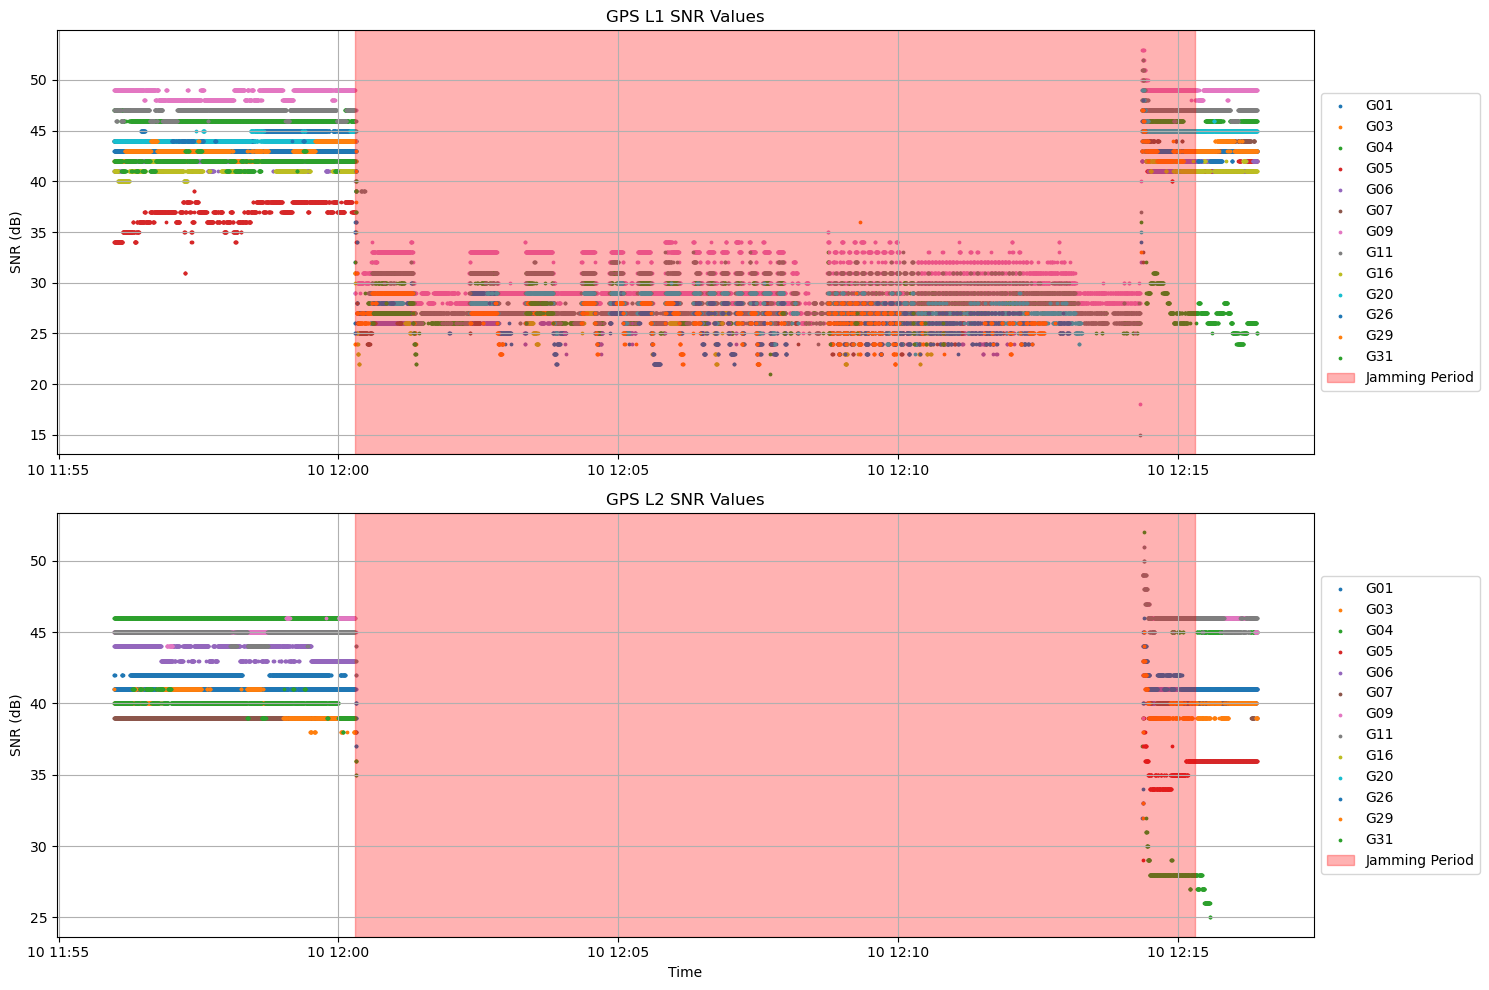

In [109]:
# Filter only GPS satellites (those starting with 'G')
gps_data = rinex_data[rinex_data['satellite'].str.startswith('G')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 SNR
plt.subplot(2, 1, 1)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    # Filter out unrealistic SNR values (greater than 100)
    valid_snr = sat_data.copy()
    valid_snr.loc[valid_snr['snr_L1'] > 100, 'snr_L1'] = np.nan
    valid_snr.loc[valid_snr['snr_L1'] < 0, 'snr_L1'] = np.nan
    plt.scatter(valid_snr['time'], valid_snr['snr_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')


plt.title('GPS L1 SNR Values')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 SNR
plt.subplot(2, 1, 2)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['snr_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L2 SNR Values')
plt.xlabel('Time')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

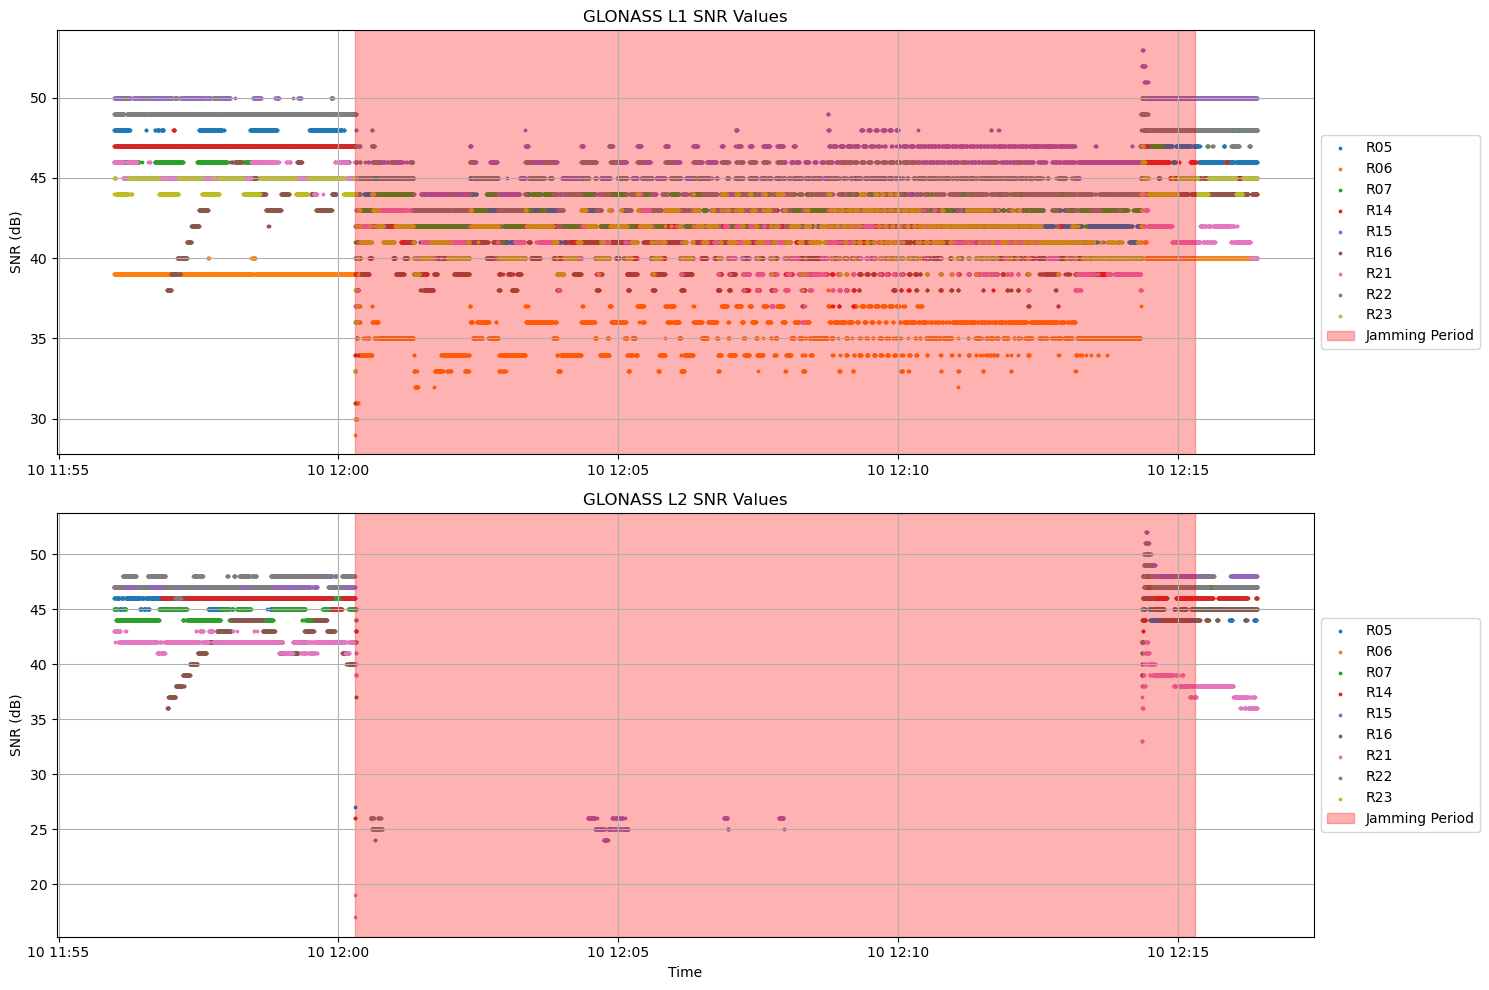

In [110]:
# Filter only GLONASS satellites (those starting with 'R')
glonass_data = rinex_data[rinex_data['satellite'].str.startswith('R')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 SNR
plt.subplot(2, 1, 1)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    # Filter out unrealistic SNR values (greater than 100)
    valid_snr = sat_data.copy()
    valid_snr.loc[valid_snr['snr_L1'] > 100, 'snr_L1'] = np.nan
    plt.scatter(valid_snr['time'], valid_snr['snr_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')

plt.title('GLONASS L1 SNR Values')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 SNR
plt.subplot(2, 1, 2)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['snr_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L2 SNR Values')
plt.xlabel('Time')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

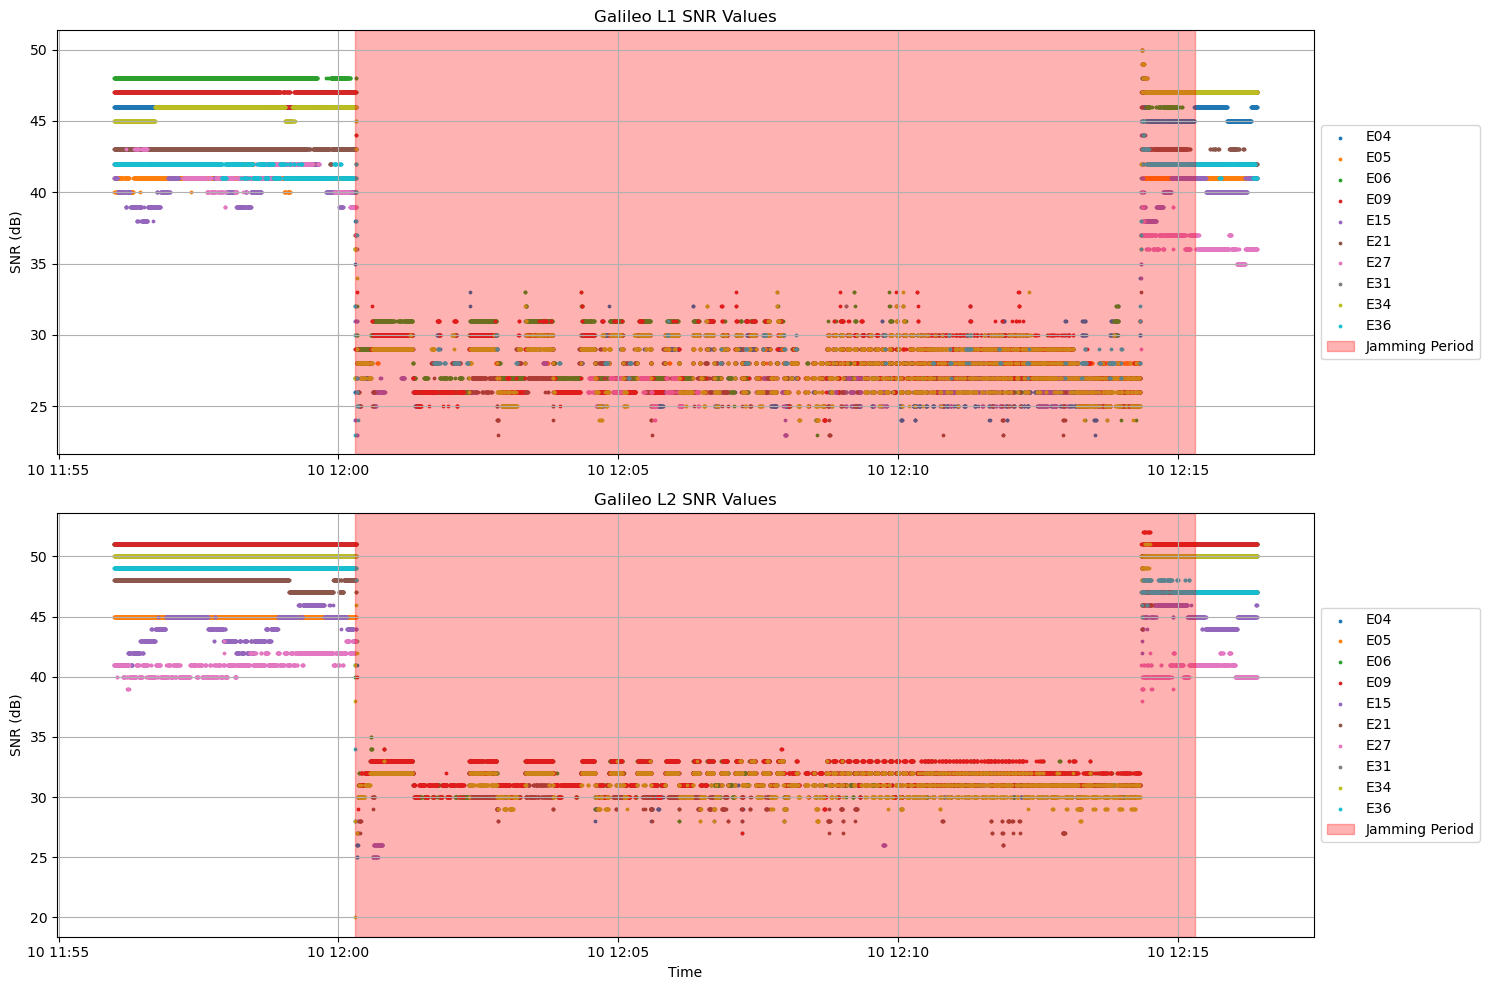

In [111]:
# Filter only Galileo satellites (those starting with 'E')
galileo_data = rinex_data[rinex_data['satellite'].str.startswith('E')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 SNR
plt.subplot(2, 1, 1)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    # Filter out unrealistic SNR values (greater than 100)
    valid_snr = sat_data.copy()
    valid_snr.loc[valid_snr['snr_L1'] > 100, 'snr_L1'] = np.nan
    plt.scatter(valid_snr['time'], valid_snr['snr_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')


plt.title('Galileo L1 SNR Values')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 SNR
plt.subplot(2, 1, 2)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['snr_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L2 SNR Values')
plt.xlabel('Time')
plt.ylabel('SNR (dB)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

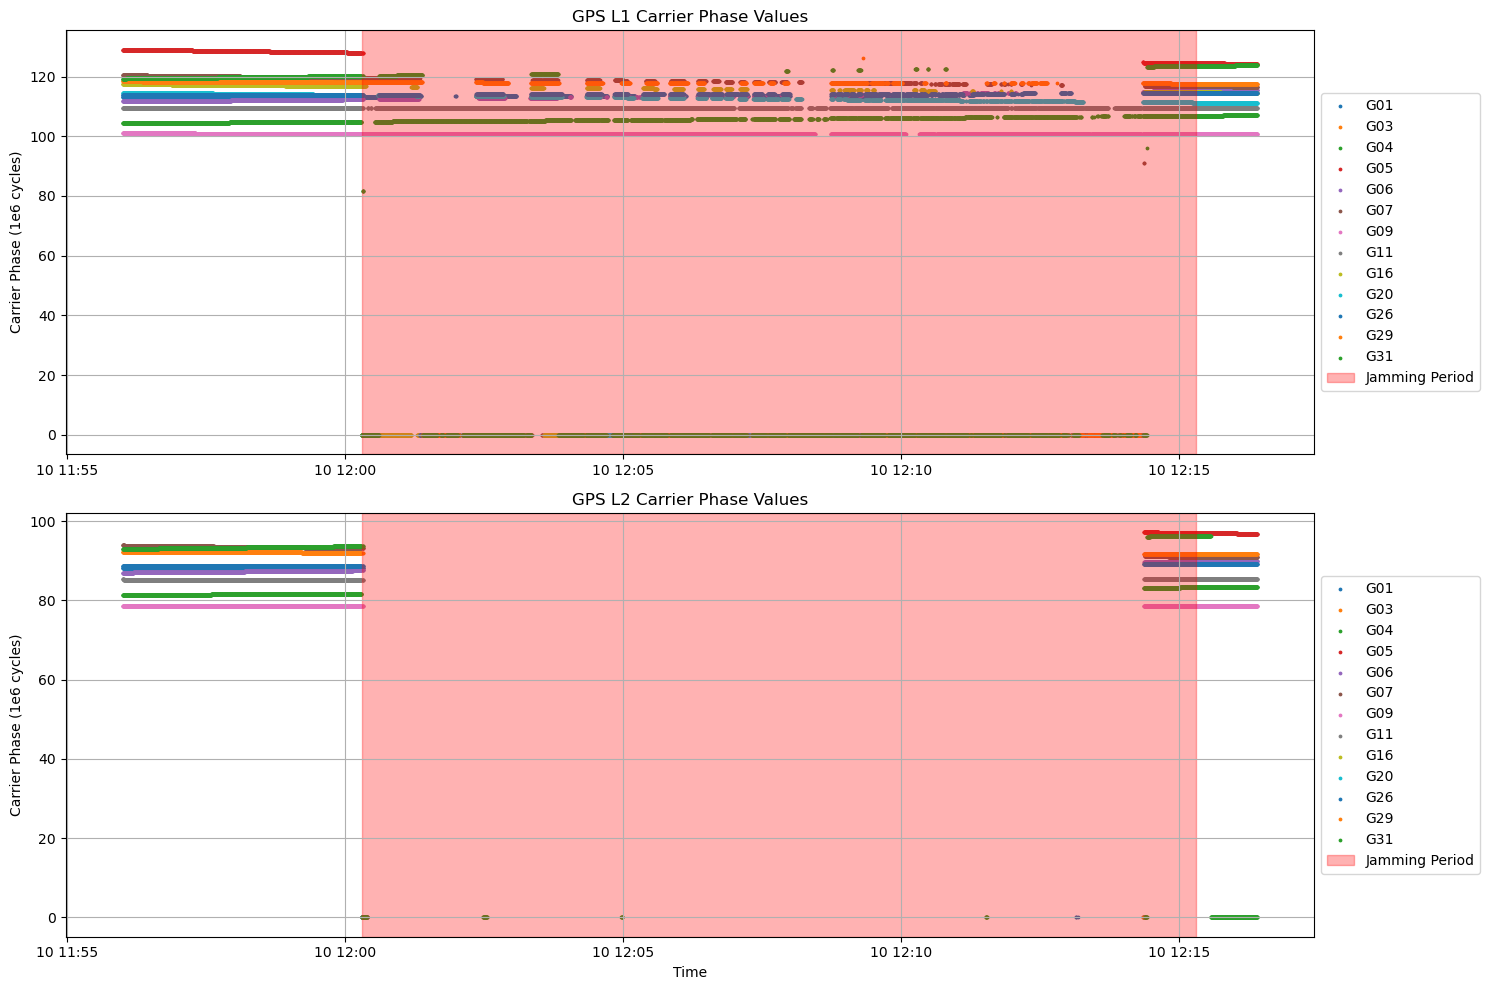

In [112]:
# Filter only GPS satellites (those starting with 'G')
gps_data = rinex_data[rinex_data['satellite'].str.startswith('G')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 carrier phase
plt.subplot(2, 1, 1)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L1 Carrier Phase Values')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 carrier phase
plt.subplot(2, 1, 2)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L2']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L2 Carrier Phase Values')
plt.xlabel('Time')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

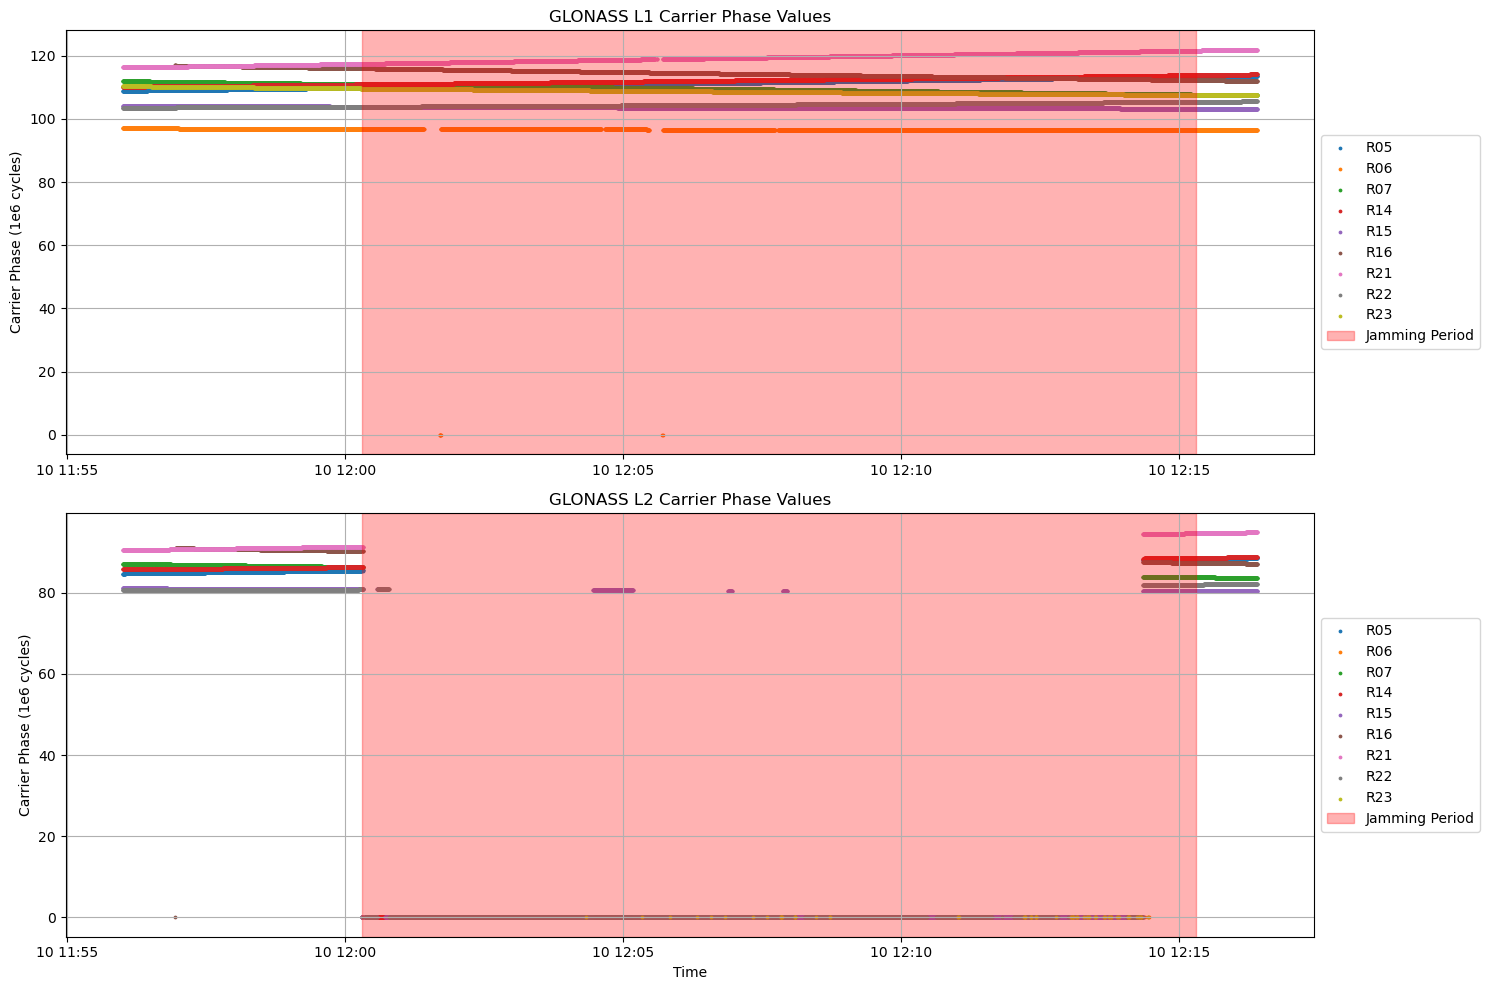

In [113]:
# Filter only GLONASS satellites (those starting with 'R')
glonass_data = rinex_data[rinex_data['satellite'].str.startswith('R')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 carrier phase
plt.subplot(2, 1, 1)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L1 Carrier Phase Values')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 carrier phase
plt.subplot(2, 1, 2)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L2']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L2 Carrier Phase Values')
plt.xlabel('Time')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

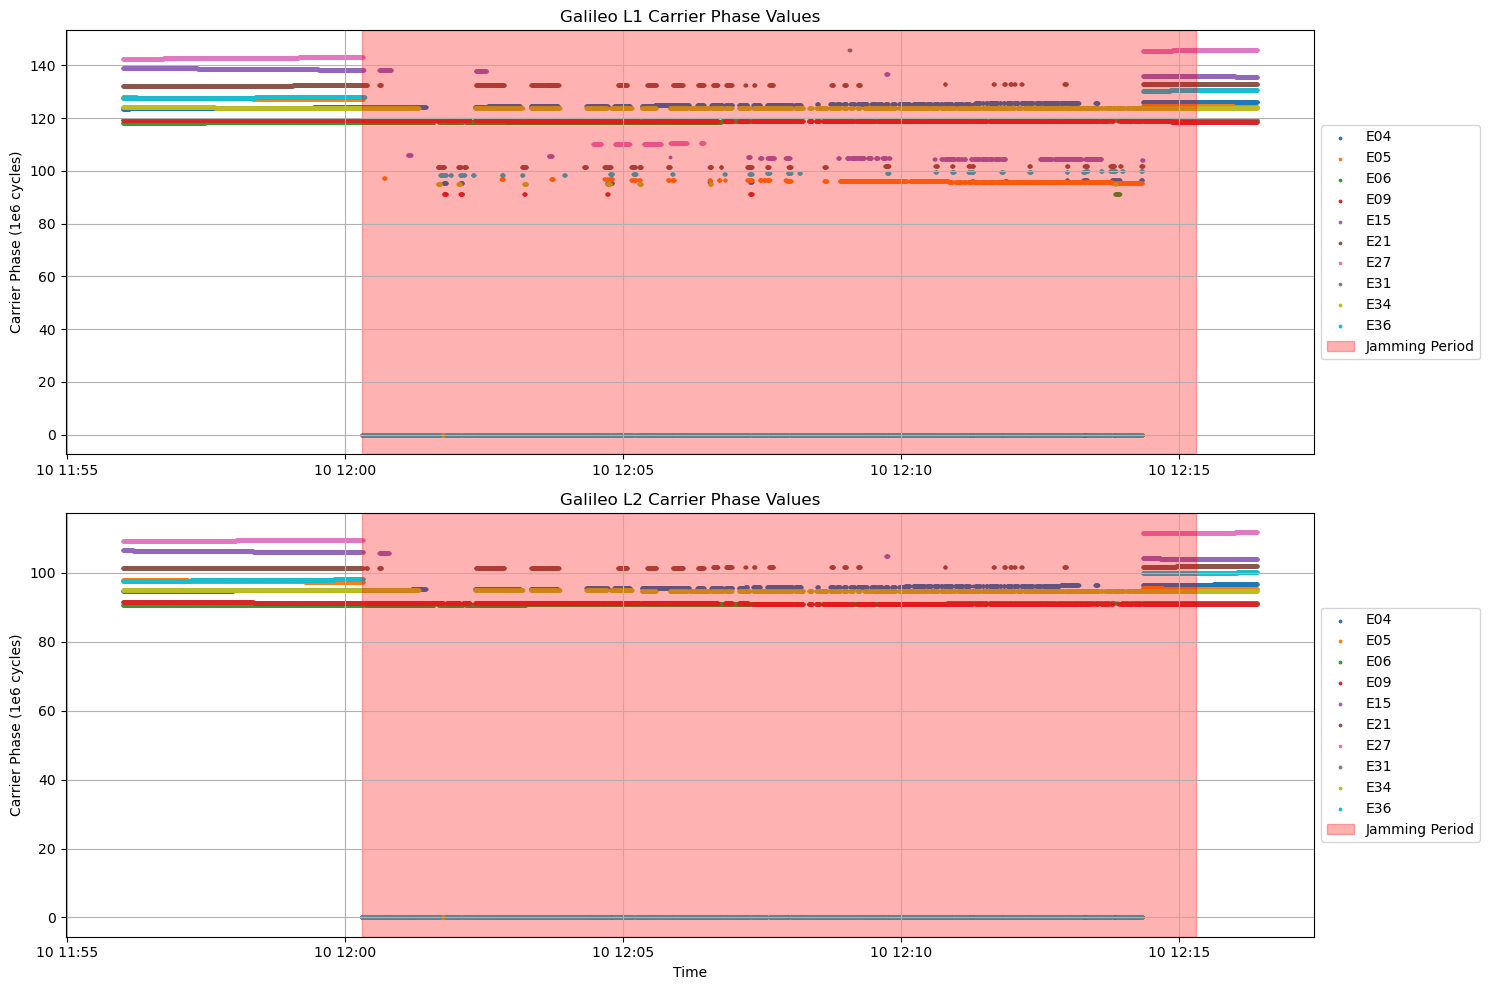

In [114]:
# Filter only Galileo satellites (those starting with 'E')
galileo_data = rinex_data[rinex_data['satellite'].str.startswith('E')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 carrier phase
plt.subplot(2, 1, 1)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L1 Carrier Phase Values')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 carrier phase
plt.subplot(2, 1, 2)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['carrier_phase_L2']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L2 Carrier Phase Values')
plt.xlabel('Time')
plt.ylabel('Carrier Phase (1e6 cycles)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

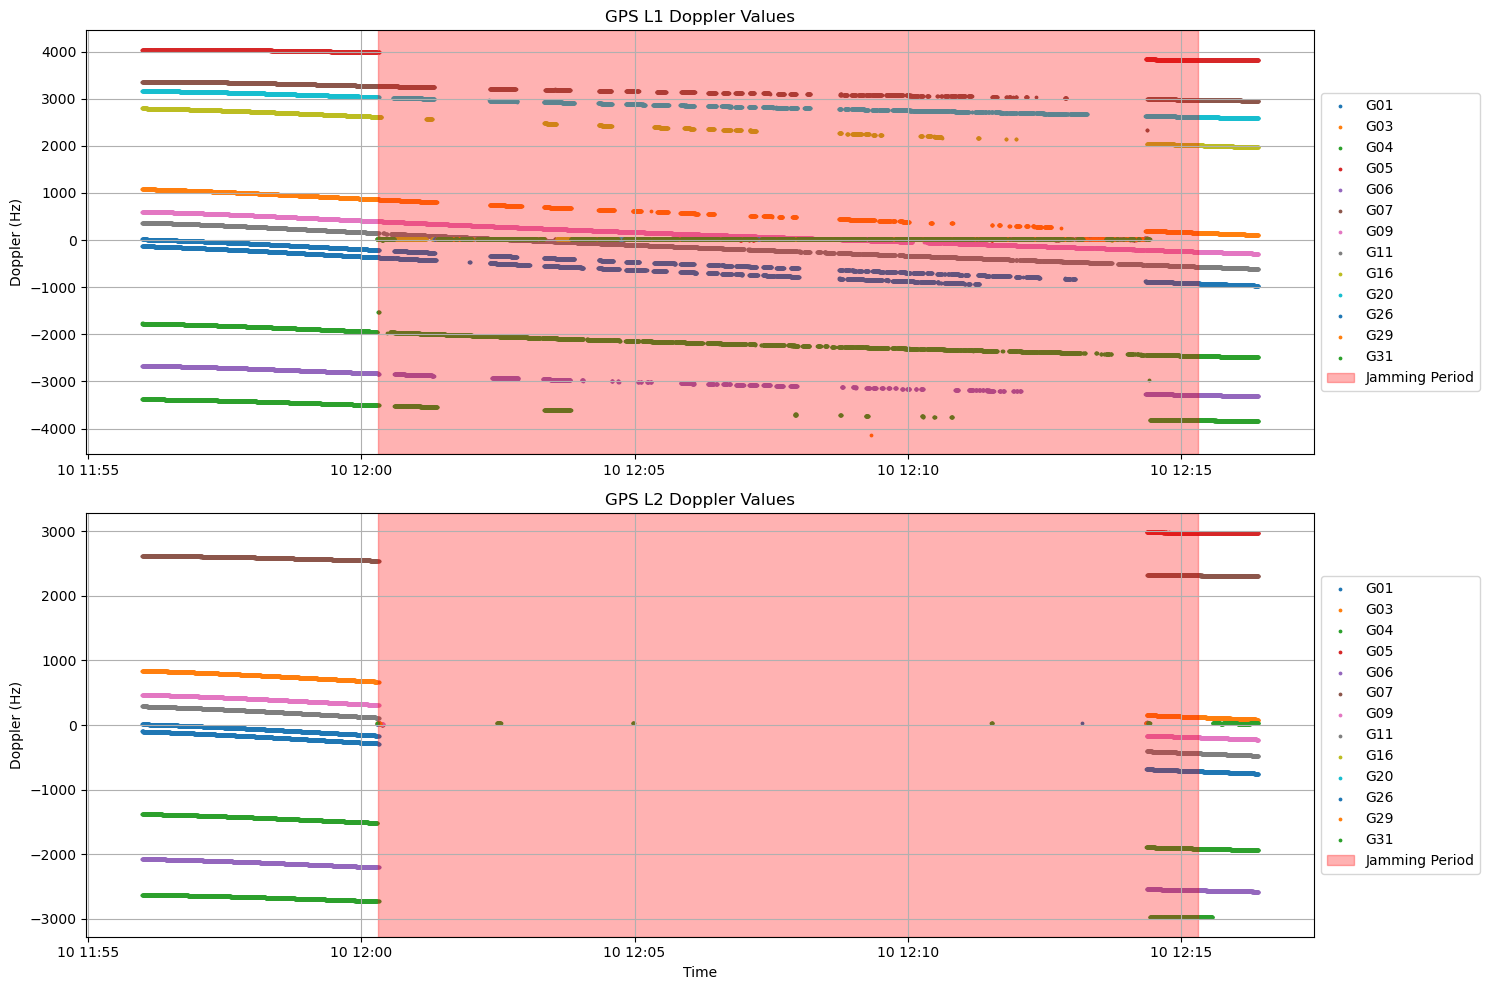

In [115]:
# Filter only GPS satellites (those starting with 'G')
gps_data = rinex_data[rinex_data['satellite'].str.startswith('G')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Doppler
plt.subplot(2, 1, 1)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L1 Doppler Values')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Doppler
plt.subplot(2, 1, 2)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L2 Doppler Values')
plt.xlabel('Time')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()


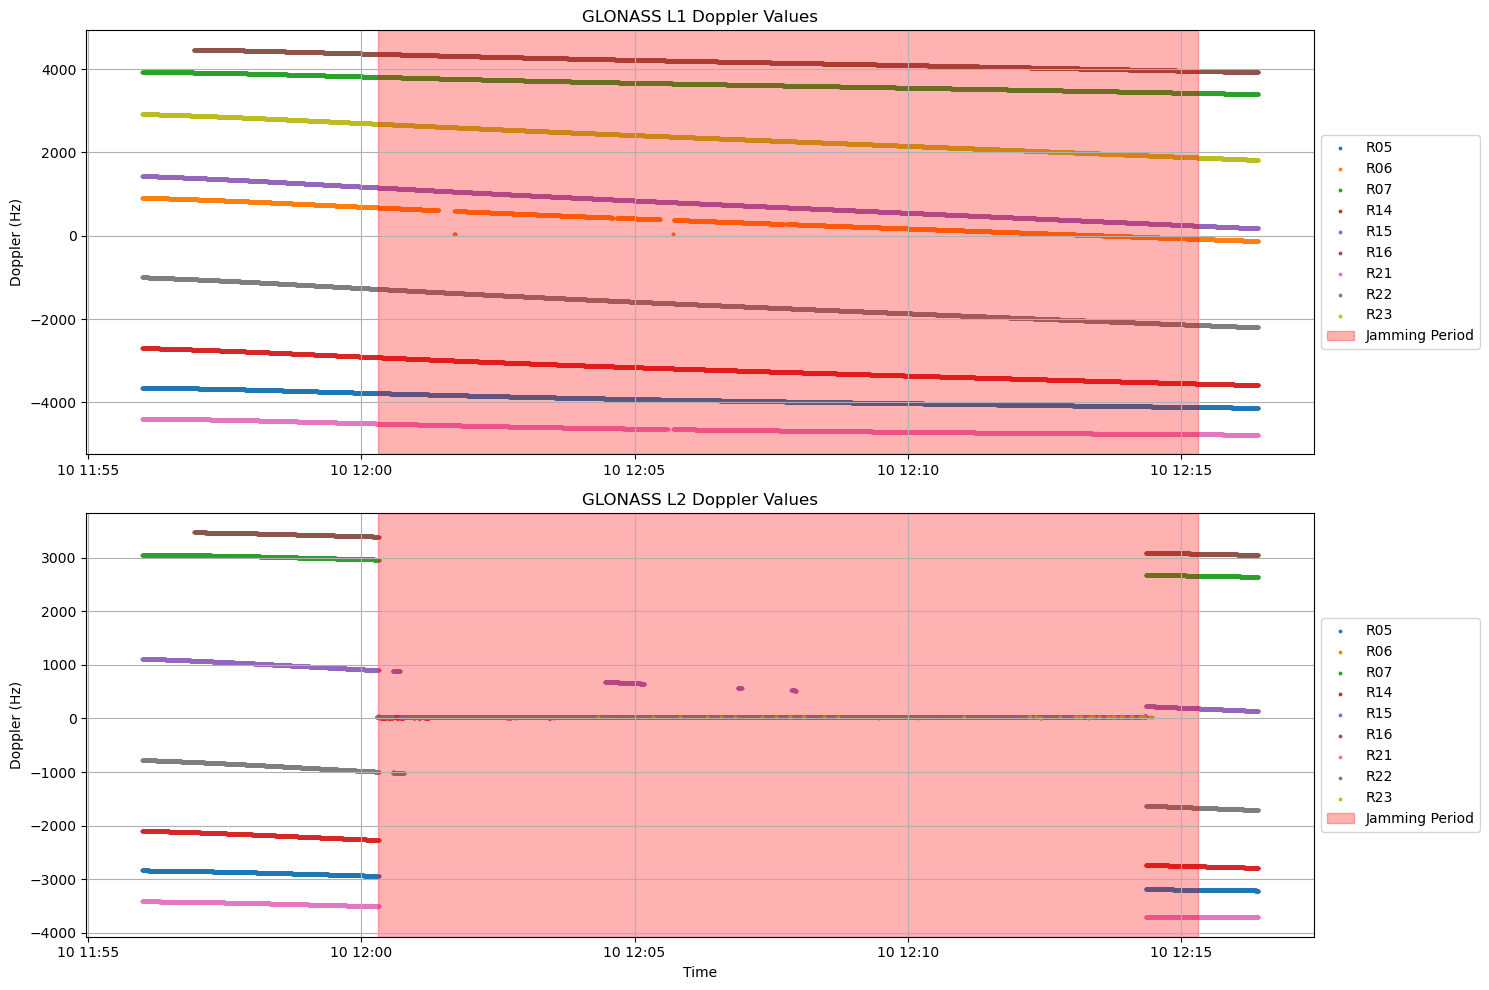

In [116]:
# Filter only GLONASS satellites (those starting with 'R')
glonass_data = rinex_data[rinex_data['satellite'].str.startswith('R')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Doppler
plt.subplot(2, 1, 1)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L1 Doppler Values')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Doppler
plt.subplot(2, 1, 2)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L2 Doppler Values')
plt.xlabel('Time')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

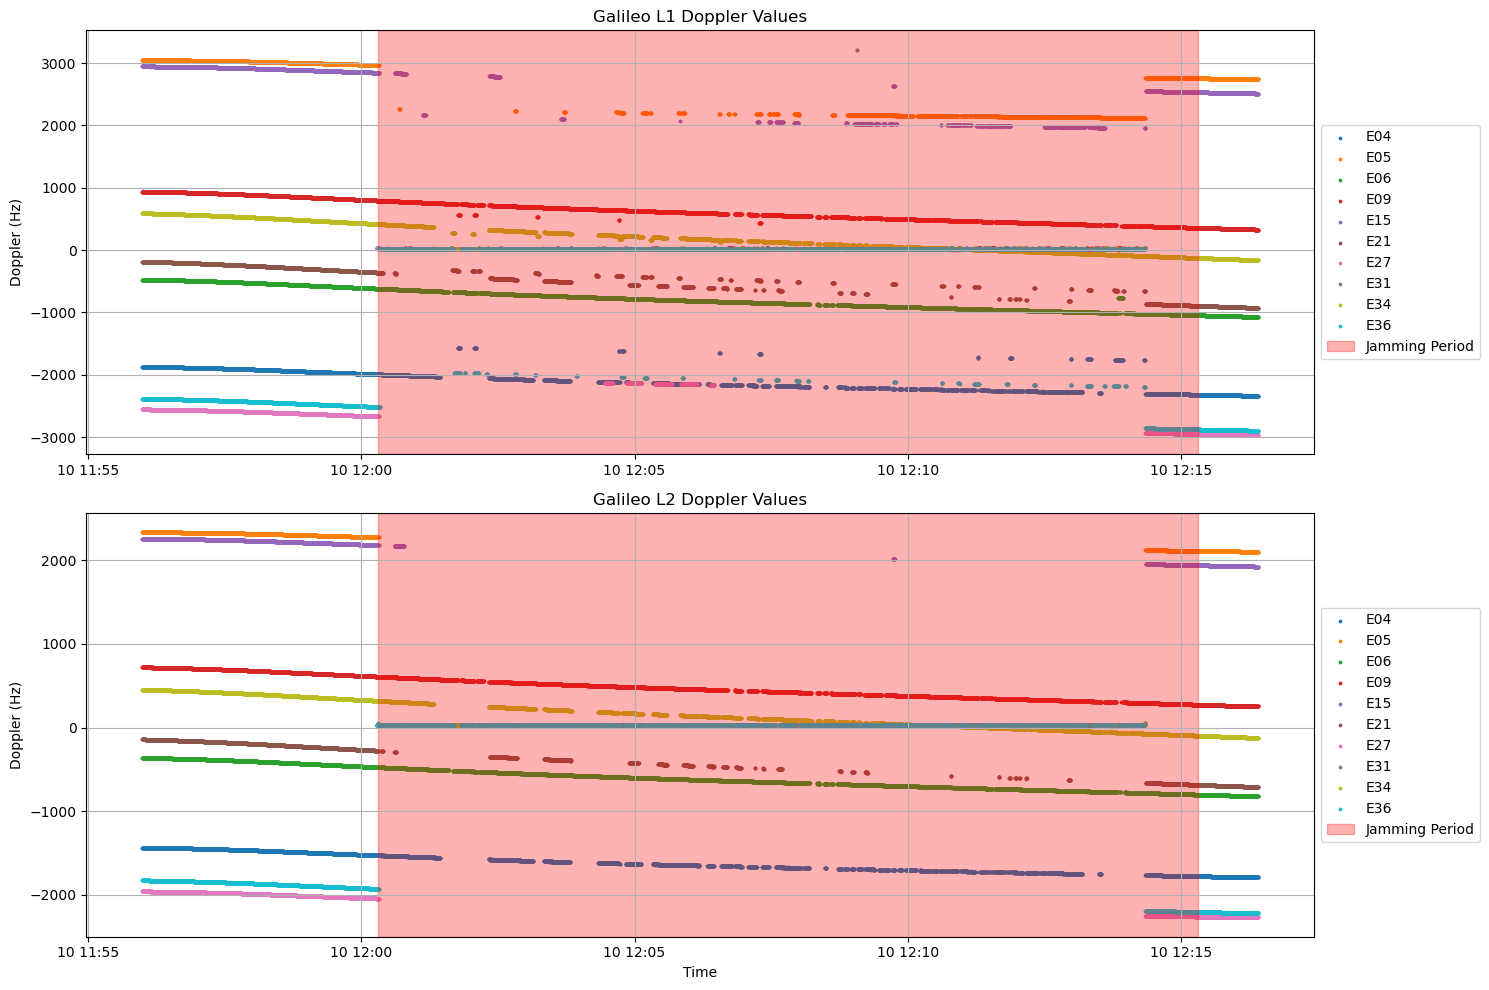

In [117]:

# Filter only Galileo satellites (those starting with 'E')
galileo_data = rinex_data[rinex_data['satellite'].str.startswith('E')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Doppler 
plt.subplot(2, 1, 1)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L1'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L1 Doppler Values')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Doppler
plt.subplot(2, 1, 2)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['doppler_L2'], s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L2 Doppler Values')
plt.xlabel('Time')
plt.ylabel('Doppler (Hz)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

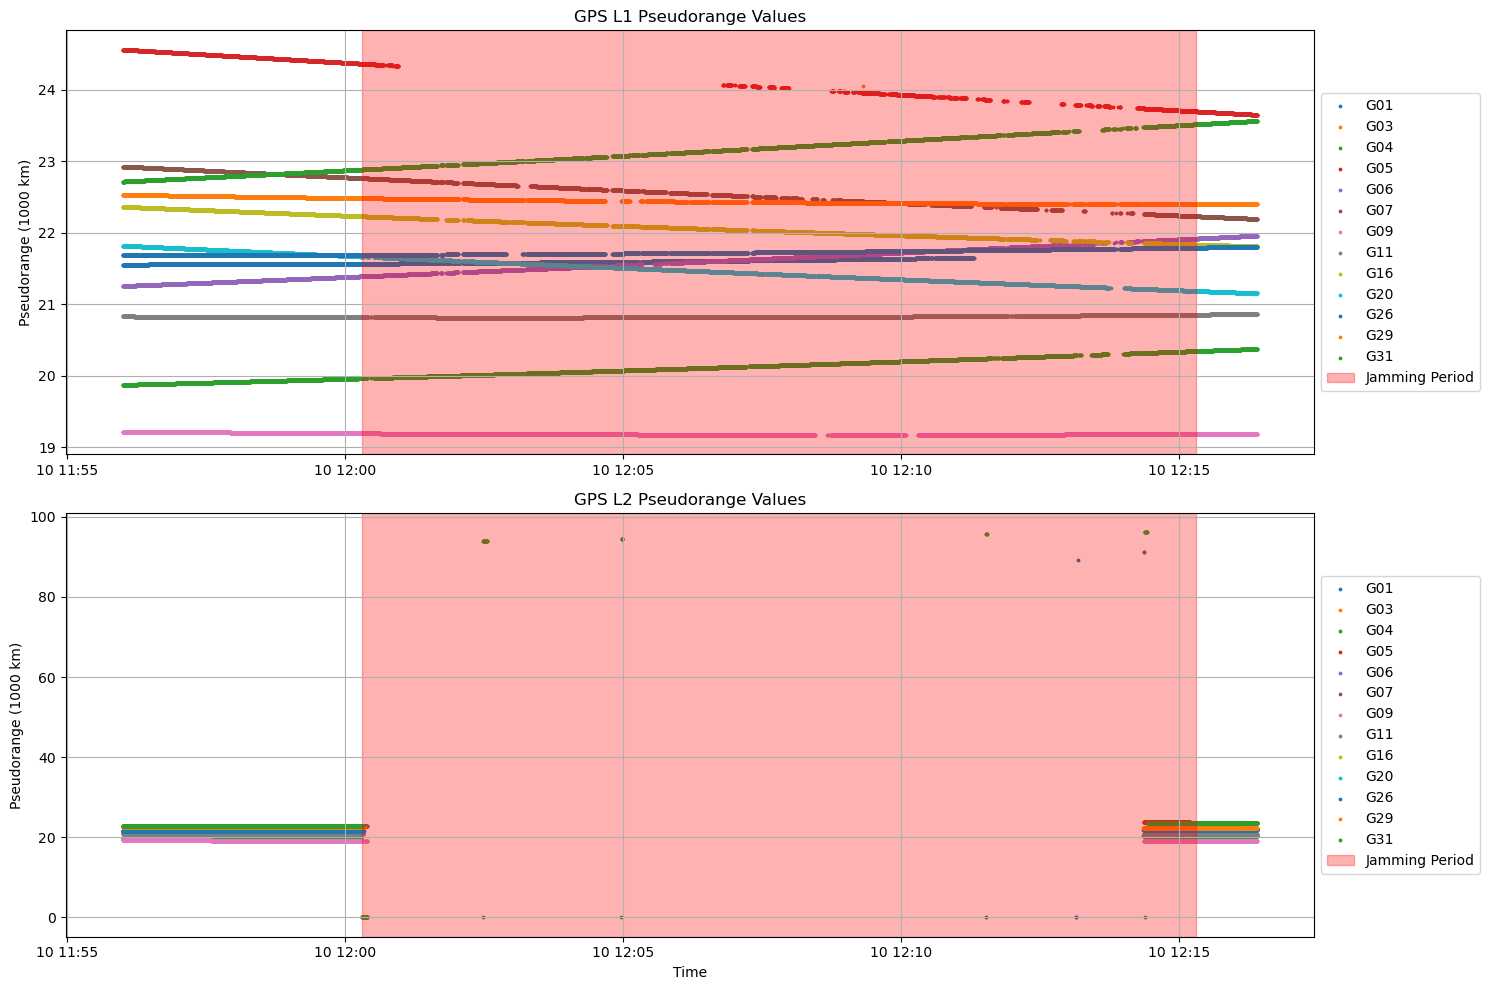

In [118]:
# Filter only GPS satellites (those starting with 'G')
gps_data = rinex_data[rinex_data['satellite'].str.startswith('G')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Pseudorange
plt.subplot(2, 1, 1)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L1 Pseudorange Values')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Pseudorange
plt.subplot(2, 1, 2)
for sat in sorted(gps_data['satellite'].unique()):
    sat_data = gps_data[gps_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L2']/1e6, s=3, label=sat)
for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GPS L2 Pseudorange Values')
plt.xlabel('Time')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

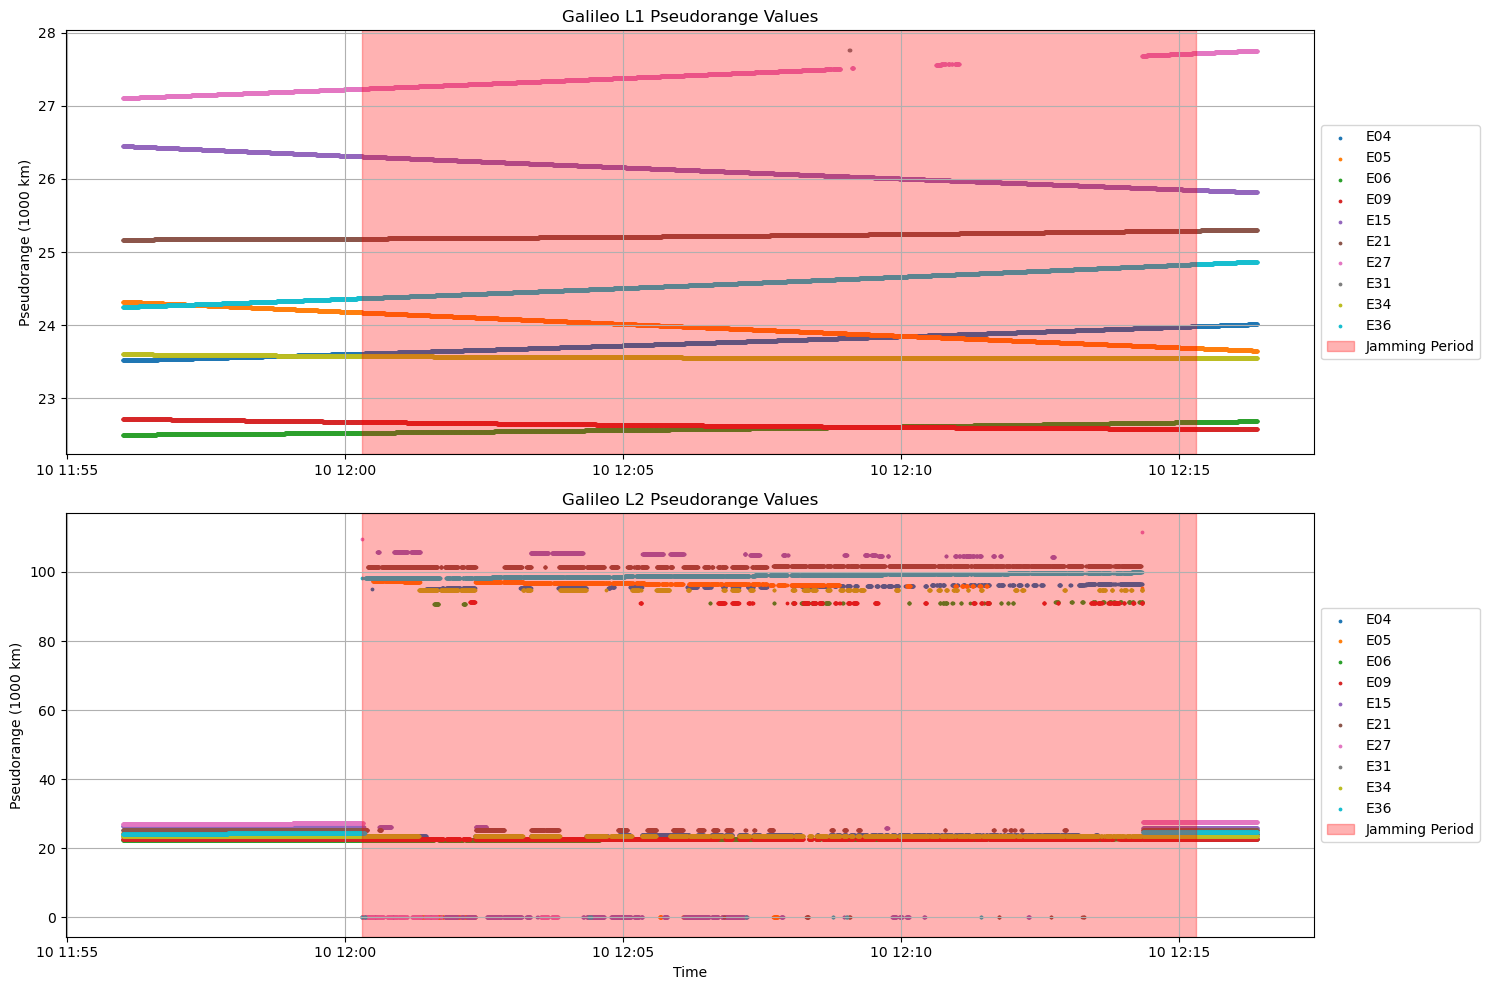

In [119]:
# Filter only Galileo satellites (those starting with 'E')
galileo_data = rinex_data[rinex_data['satellite'].str.startswith('E')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Pseudorange
plt.subplot(2, 1, 1)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L1 Pseudorange Values')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Pseudorange
plt.subplot(2, 1, 2)
for sat in sorted(galileo_data['satellite'].unique()):
    sat_data = galileo_data[galileo_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L2']/1e6, s=3, label=sat)
for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Galileo L2 Pseudorange Values')
plt.xlabel('Time')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

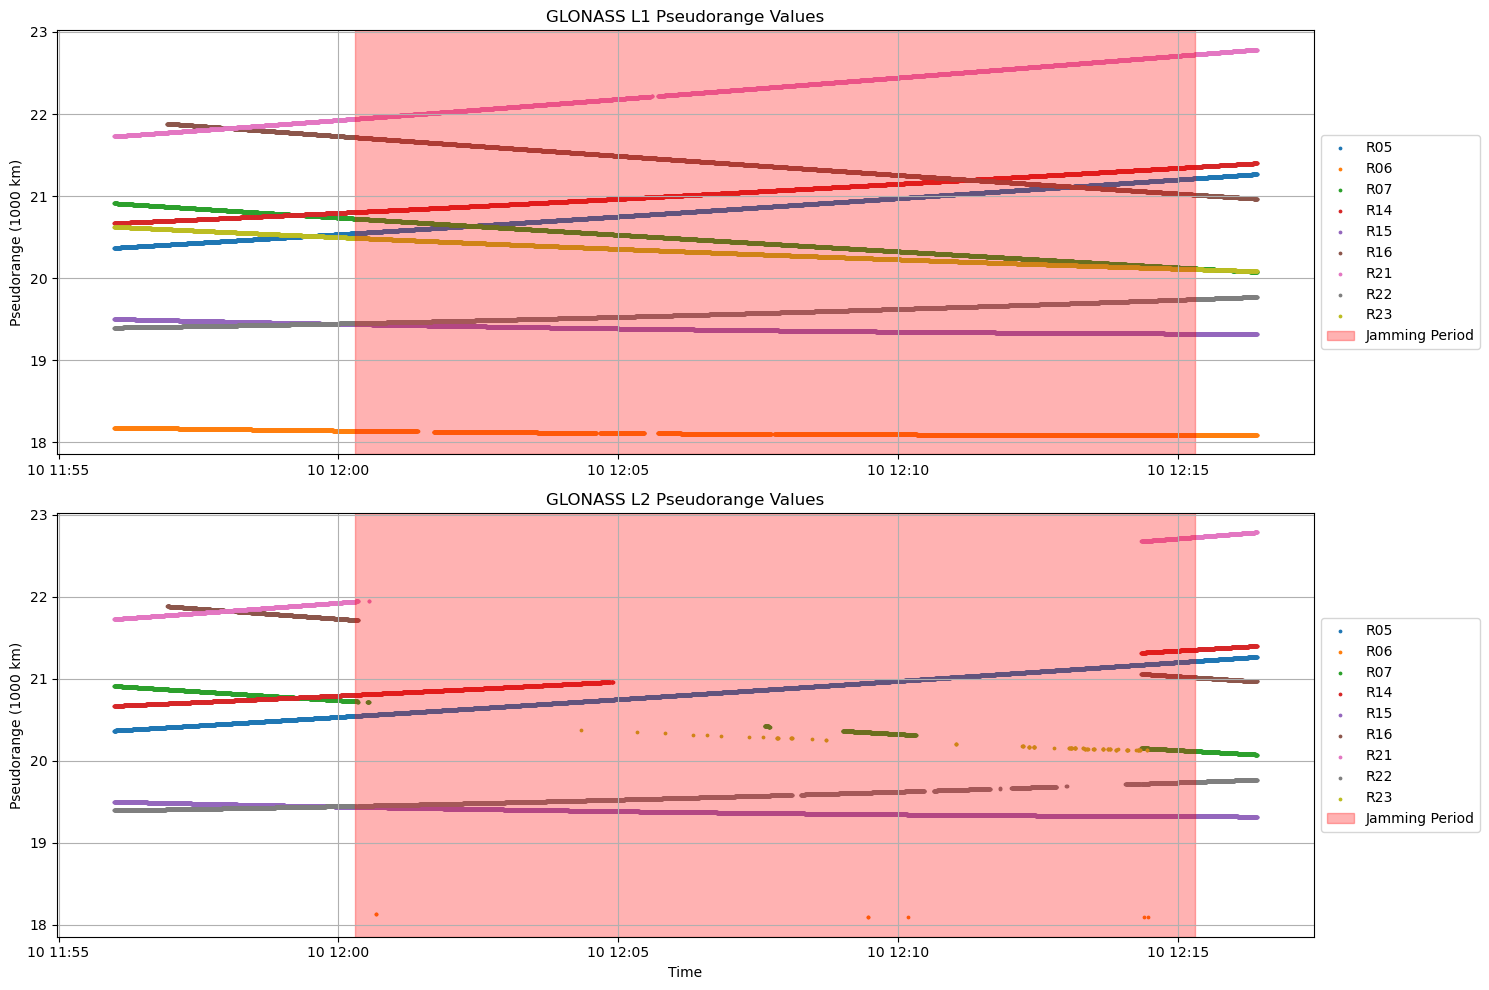

In [120]:
# Filter only GLONASS satellites (those starting with 'R')
glonass_data = rinex_data[rinex_data['satellite'].str.startswith('R')]

# Create figure with two subplots
plt.figure(figsize=(15, 10))

# Plot L1 Pseudorange
plt.subplot(2, 1, 1)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L1']/1e6, s=3, label=sat)

for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L1 Pseudorange Values')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# Plot L2 Pseudorange
plt.subplot(2, 1, 2)
for sat in sorted(glonass_data['satellite'].unique()):
    sat_data = glonass_data[glonass_data['satellite'] == sat]
    plt.scatter(sat_data['time'], sat_data['pseudorange_L2']/1e6, s=3, label=sat)
for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('GLONASS L2 Pseudorange Values')
plt.xlabel('Time')
plt.ylabel('Pseudorange (1000 km)')
plt.grid(True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Enables 3D plotting
import os
from scipy.ndimage import gaussian_filter  # For interpolation / smoothing

# Create an output directory to store the CAF plots for all satellites
output_dir = "caf_plots_all"
os.makedirs(output_dir, exist_ok=True)

# Filter only GPS satellite data from your DataFrame
gps_data = rinex_data[rinex_data['satellite'].str.startswith('G')]
satellites = sorted(gps_data['satellite'].unique())

print(f"Found {len(satellites)} GPS satellites: {', '.join(satellites)}")

# Loop over each satellite to compute and plot its CAF
for satellite in satellites:
    sat_data = gps_data[gps_data['satellite'] == satellite]
    
    # Ensure the required columns exist
    if 'pseudorange_L1' not in sat_data.columns or 'doppler_L1' not in sat_data.columns:
        print(f"Skipping {satellite}: Missing required columns.")
        continue

    # Extract pseudorange (code phase) and Doppler values, and clean the data
    code_phase = sat_data['pseudorange_L1'].values
    doppler = sat_data['doppler_L1'].values
    valid_mask = np.isfinite(code_phase) & np.isfinite(doppler)
    code_phase = code_phase[valid_mask]
    doppler = doppler[valid_mask]

    # Check that there are enough data points
    if len(code_phase) < 20:
        print(f"Skipping {satellite}: Not enough valid data points.")
        continue

    print(f"Creating CAF plot for {satellite} with {len(code_phase)} data points.")

    # Normalize code phase values to a fixed range (e.g., 0 to 1024 chips)
    code_phase_min = code_phase.min()
    code_phase_max = code_phase.max()
    code_phase_norm = ((code_phase - code_phase_min) / (code_phase_max - code_phase_min)) * 1024

    # Define Doppler range and clip values to that range
    doppler_range = [-5000, 5000]
    doppler_clamped = np.clip(doppler, doppler_range[0], doppler_range[1])

    # Compute a 2D histogram to serve as the CAF proxy
    nbins = 200  # Adjust bin count as needed
    H, xedges, yedges = np.histogram2d(
        doppler_clamped, code_phase_norm,
        bins=nbins,
        range=[doppler_range, [0, 1024]]
    )
    H_surface = H.T  # Transpose so that rows correspond to code phase and columns to Doppler

    # Apply Gaussian filtering for interpolation/smoothing
    H_smooth = gaussian_filter(H_surface, sigma=3)
    
    # Normalize the smoothed correlation values to be between 0 and 1
    H_smooth_norm = H_smooth / H_smooth.max()

    # Create meshgrid for 3D surface plotting
    x_centers = (xedges[:-1] + xedges[1:]) / 2  # Doppler centers
    y_centers = (yedges[:-1] + yedges[1:]) / 2  # Code phase centers
    X, Y = np.meshgrid(x_centers, y_centers)

    # Set up the 3D plot
    fig = plt.figure(figsize=(10, 6), dpi=300)
    ax = fig.add_subplot(111, projection='3d')

    # Plot the normalized, smoothed CAF as a 3D surface
    surf = ax.plot_surface(
        X, Y, H_smooth_norm,
        cmap='viridis',
        linewidth=0,
        antialiased=False,
        shade=True
    )

    # Fix the color bar range from 0 to 1
    surf.set_clim(0, 1)

    # Configure axis labels and title
    ax.set_xlabel('Doppler [Hz]', labelpad=10)
    ax.set_ylabel('Code Phase [chips]', labelpad=10)
    ax.set_zlabel('Normalized Correlation Amplitude', labelpad=10)

    # Set axis limits
    ax.set_xlim(doppler_range[0], doppler_range[1])
    ax.set_ylim(0, 1024)
    ax.set_zlim(0, 1)  # Now the correlation amplitude is normalized between 0 and 1

    # Set a viewing angle
    ax.view_init(elev=25, azim=235)

    # Add a colorbar with fixed range
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Normalized Correlation Amplitude')

    plt.tight_layout()

    # Save the plot for the current satellite
    out_file = os.path.join(output_dir, f"CAF_{satellite}.png")
    plt.savefig(out_file, bbox_inches='tight', facecolor='white')
    plt.close()

    print(f"Saved CAF plot for {satellite} to {out_file}")

print("Completed creating CAF plots for all satellites.")


Found 13 GPS satellites: G01, G03, G04, G05, G06, G07, G09, G11, G16, G20, G26, G29, G31
Creating CAF plot for G01 with 4519 data points.
Saved CAF plot for G01 to caf_plots_all/CAF_G01.png
Skipping G03: Not enough valid data points.
Creating CAF plot for G04 with 5852 data points.
Saved CAF plot for G04 to caf_plots_all/CAF_G04.png
Creating CAF plot for G05 with 3031 data points.
Saved CAF plot for G05 to caf_plots_all/CAF_G05.png
Creating CAF plot for G06 with 5567 data points.
Saved CAF plot for G06 to caf_plots_all/CAF_G06.png
Creating CAF plot for G07 with 4979 data points.
Saved CAF plot for G07 to caf_plots_all/CAF_G07.png
Creating CAF plot for G09 with 5974 data points.
Saved CAF plot for G09 to caf_plots_all/CAF_G09.png
Creating CAF plot for G11 with 6073 data points.
Saved CAF plot for G11 to caf_plots_all/CAF_G11.png
Creating CAF plot for G16 with 5540 data points.
Saved CAF plot for G16 to caf_plots_all/CAF_G16.png
Creating CAF plot for G20 with 5901 data points.
Saved CAF 

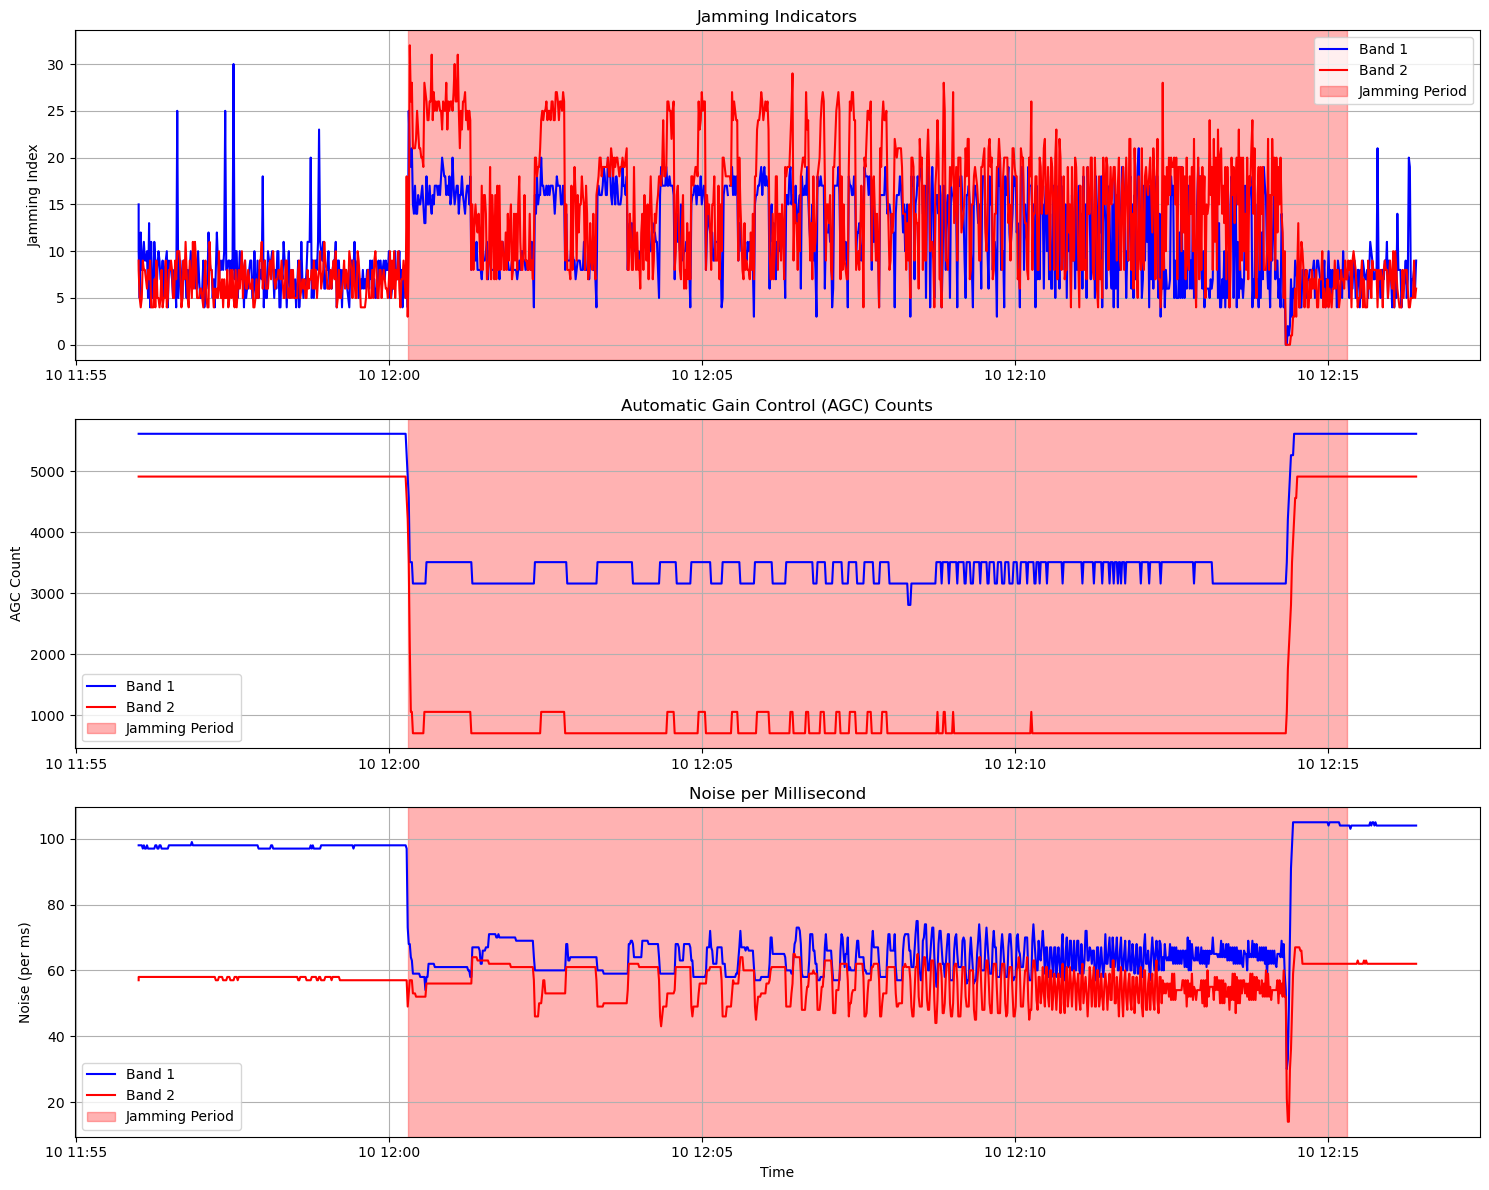

In [122]:
# Convert real_time to datetime
mon_rf_data['real_time'] = pd.to_datetime(mon_rf_data['real_time'])

# Create figure with multiple subplots
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12))

# Plot jamming indicators
ax1.plot(mon_rf_data['real_time'], mon_rf_data['jamInd_01'], label='Band 1', color='blue')
ax1.plot(mon_rf_data['real_time'], mon_rf_data['jamInd_02'], label='Band 2', color='red')
for start, end in adjusted_attack_periods:
    ax1.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax1.set_title('Jamming Indicators')
ax1.set_ylabel('Jamming Index')
ax1.grid(True)
ax1.legend()

# Plot AGC counts
ax2.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_01'], label='Band 1', color='blue')
ax2.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_02'], label='Band 2', color='red')
for start, end in adjusted_attack_periods:
    ax2.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax2.set_title('Automatic Gain Control (AGC) Counts')
ax2.set_ylabel('AGC Count')
ax2.grid(True)
ax2.legend()

# Plot noise per millisecond
ax3.plot(mon_rf_data['real_time'], mon_rf_data['noisePerMS_01'], label='Band 1', color='blue')
ax3.plot(mon_rf_data['real_time'], mon_rf_data['noisePerMS_02'], label='Band 2', color='red')
for start, end in adjusted_attack_periods:
    ax3.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax3.set_title('Noise per Millisecond')
ax3.set_xlabel('Time')
ax3.set_ylabel('Noise (per ms)')
ax3.grid(True)
ax3.legend()

plt.tight_layout()
plt.show()

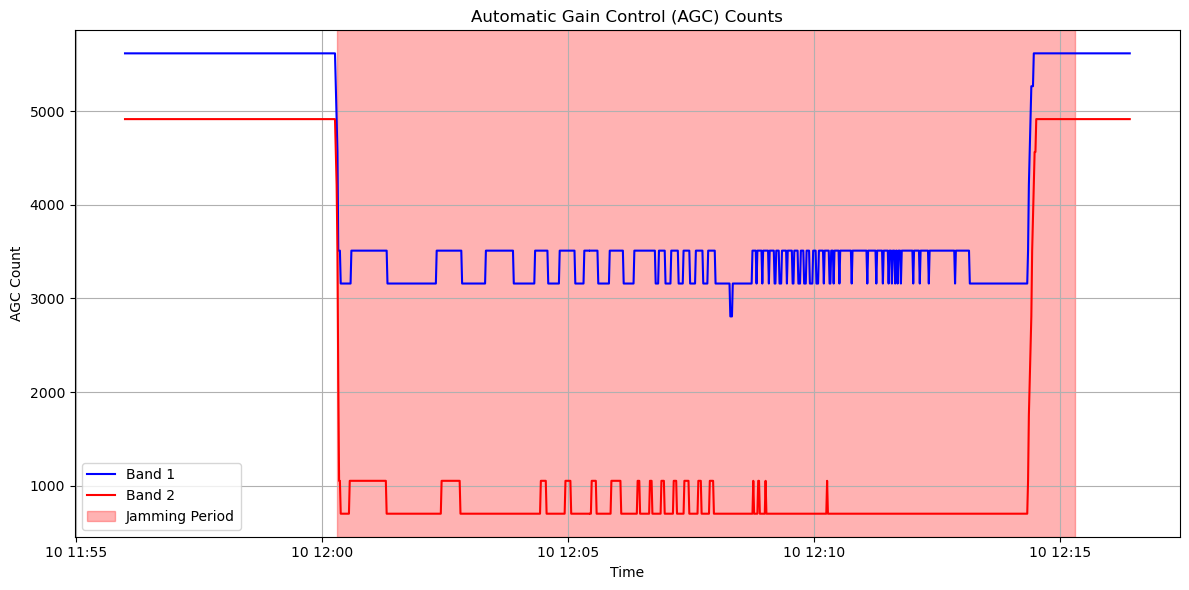

In [123]:
# Plot AGC counts
plt.figure(figsize=(12, 6))
plt.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_01'], label='Band 1', color='blue')
plt.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_02'], label='Band 2', color='red')
for start, end in adjusted_attack_periods:
    plt.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
plt.title('Automatic Gain Control (AGC) Counts')
plt.ylabel('AGC Count')
plt.xlabel('Time')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_29465/3877907702.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


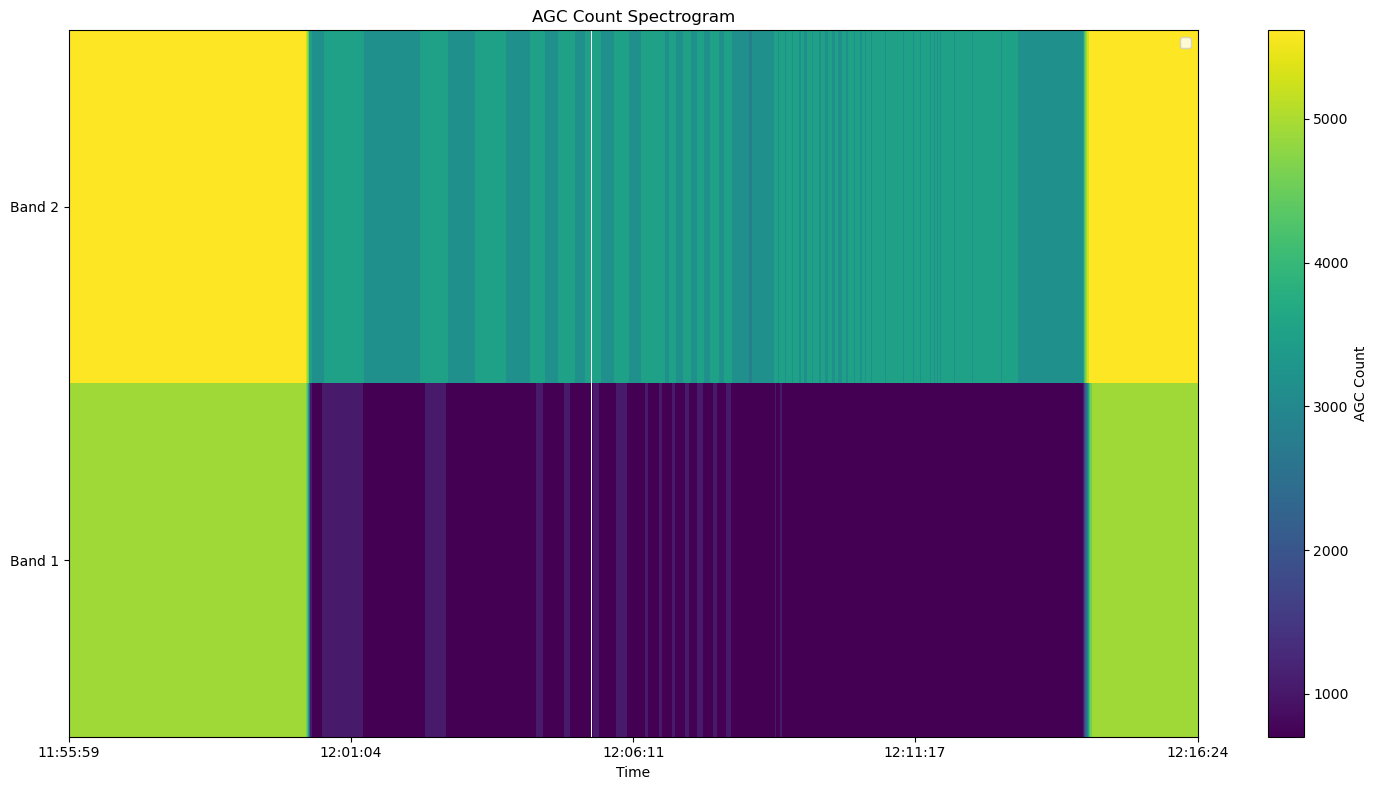

In [124]:
# Convert time to datetime if not already
mon_rf_data['real_time'] = pd.to_datetime(mon_rf_data['real_time'])

# Create a figure
plt.figure(figsize=(15, 8))

# Extract AGC data for both bands
agc_data = np.vstack([mon_rf_data['agcCnt_01'], mon_rf_data['agcCnt_02']])

# Create time values for x-axis
time_values = mon_rf_data['real_time']
time_indices = np.arange(len(time_values))

# Plot the spectrogram using imshow
img = plt.imshow(agc_data, 
                 aspect='auto',
                 extent=[time_indices[0], time_indices[-1], 0, 2],
                 cmap='viridis',
                 interpolation='nearest')

# Add colorbar
plt.colorbar(img, label='AGC Count')

# Format x-axis with timestamps
xticks = np.linspace(0, len(time_values)-1, 5, dtype=int)
plt.xticks(xticks, [time_values.iloc[i].strftime('%H:%M:%S') for i in xticks])

# Add labels and title
plt.yticks([0.5, 1.5], ['Band 1', 'Band 2'])
plt.xlabel('Time')
plt.title('AGC Count Spectrogram')



plt.legend()
plt.tight_layout()
plt.show()

In [125]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import matplotlib.dates as mdates
# from scipy.interpolate import interp1d
# import pywt
# from matplotlib.colors import LogNorm

# def analyze_agc_wavelet(mon_rf_data, band_column='agcCnt_01', wavelet='morl', scales=None):
#     """
#     Performs wavelet analysis on AGC data to reveal time-frequency characteristics.
    
#     Parameters:
#     mon_rf_data (DataFrame): DataFrame containing AGC data
#     band_column (str): Column name for the AGC data to analyze ('agcCnt_01' or 'agcCnt_02')
#     wavelet (str): Wavelet type to use (e.g., 'morl', 'mexh', 'cmor', 'gaus')
#     scales (array, optional): Scales for wavelet transform. If None, auto-generated.
    
#     Returns:
#     dict: Wavelet analysis results
#     """
#     # Extract signal
#     signal = mon_rf_data[band_column].values
    
#     # Normalize signal for better wavelet analysis
#     signal = (signal - np.mean(signal)) / np.std(signal)
    
#     # Get time information for plotting
#     time = mon_rf_data['real_time']
#     time_nums = mdates.date2num(time)
    
#     # Estimate sampling rate (Hz)
#     avg_time_diff = (time_nums[-1] - time_nums[0]) / (len(time_nums) - 1)
#     fs = 1.0 / (avg_time_diff * 24 * 60 * 60)  # Convert from days to seconds
    
#     # Auto-generate scales if not provided
#     if scales is None:
#         # Create scales that correspond to frequencies
#         # Higher scales = lower frequencies
#         scales = np.arange(1, min(128, len(signal)//2))
    
#     # Perform continuous wavelet transform
#     coefficients, frequencies = pywt.cwt(signal, scales, wavelet, 1.0/fs)
    
#     # Create figure for visualization
#     plt.figure(figsize=(15, 10))
    
#     # Plot original signal
#     plt.subplot(211)
#     plt.plot(time, signal, 'b-')
#     plt.title(f'Original AGC Signal - {band_column}')
#     plt.ylabel('Normalized Amplitude')
#     plt.grid(True, alpha=0.3)
    
#     # Format x-axis with dates
#     plt.gcf().autofmt_xdate()
    
#     # Plot wavelet scalogram
#     plt.subplot(212)
    
#     # Plot with logarithmic scale for better visibility of all components
#     plt.pcolormesh(time, frequencies, np.abs(coefficients), cmap='jet', norm=LogNorm())
#     plt.title(f'Wavelet Scalogram ({wavelet} wavelet)')
#     plt.ylabel('Frequency [Hz]')
#     plt.xlabel('Time')
    
#     # Format x-axis with dates
#     plt.gcf().autofmt_xdate()
    
#     plt.colorbar(label='Magnitude')
#     plt.tight_layout()
#     plt.show()
    
#     # Create detailed multi-wavelet comparison
#     compare_wavelets(signal, time, fs)
    
#     return {
#         'coefficients': coefficients,
#         'frequencies': frequencies,
#         'fs': fs
#     }

# def compare_wavelets(signal, time, fs):
#     """
#     Compare different wavelet types for AGC analysis.
    
#     Parameters:
#     signal (array): Normalized AGC signal
#     time (array): Time array
#     fs (float): Sampling frequency in Hz
#     """
#     # Define wavelet types to compare
#     wavelets = ['morl', 'mexh', 'cmor1.0-1.0', 'gaus1']
    
#     # Define scales - use fewer scales for faster computation
#     scales = np.arange(1, min(64, len(signal)//4))
    
#     # Create figure for comparison
#     plt.figure(figsize=(15, 12))
#     plt.suptitle('Comparison of Different Wavelet Types for AGC Analysis', fontsize=16)
    
#     # Plot original signal at the top
#     plt.subplot(len(wavelets)+1, 1, 1)
#     plt.plot(time, signal, 'b-')
#     plt.title('Original AGC Signal')
#     plt.ylabel('Amplitude')
#     plt.grid(True, alpha=0.3)
    
#     # Format x-axis with dates
#     plt.gcf().autofmt_xdate()
    
#     # Compute and plot wavelet transform for each wavelet type
#     for i, wavelet in enumerate(wavelets):
#         # Perform CWT
#         coefficients, frequencies = pywt.cwt(signal, scales, wavelet, 1.0/fs)
        
#         # Plot
#         plt.subplot(len(wavelets)+1, 1, i+2)
#         plt.pcolormesh(time, frequencies, np.abs(coefficients), cmap='jet', norm=LogNorm())
#         plt.title(f'Wavelet: {wavelet}')
#         plt.ylabel('Frequency [Hz]')
        
#         # Only show x-label for the last subplot
#         if i == len(wavelets) - 1:
#             plt.xlabel('Time')
        
#         # Format x-axis with dates
#         plt.gcf().autofmt_xdate()
    
#     plt.tight_layout(rect=[0, 0, 1, 0.97])  # Adjust for suptitle
#     plt.show()

# def extract_wavelet_features(mon_rf_data, band_column='agcCnt_01'):
#     """
#     Extract features from wavelet decomposition of AGC data.
    
#     Parameters:
#     mon_rf_data (DataFrame): DataFrame containing AGC data
#     band_column (str): Column name for the AGC data to analyze
    
#     Returns:
#     DataFrame: Features extracted from wavelet decomposition
#     """
#     # Extract and prepare signal
#     signal = mon_rf_data[band_column].values
#     signal = (signal - np.mean(signal)) / np.std(signal)
    
#     # Perform discrete wavelet transform
#     # Use 'db4' (Daubechies 4) wavelet, commonly used for signal analysis
#     wavelet = 'db4'
#     level = 5  # Decomposition level
    
#     # Perform multilevel wavelet decomposition
#     coeffs = pywt.wavedec(signal, wavelet, level=level)
    
#     # coeffs[0] is the approximation coefficients at level 5
#     # coeffs[1:] are the detail coefficients from levels 5 to 1
    
#     # Compute energy of coefficients at each level
#     energies = [np.sum(np.square(c)) for c in coeffs]
#     total_energy = sum(energies)
    
#     # Calculate relative energy in percentage
#     energy_pct = [100 * e / total_energy for e in energies]
    
#     # Compute statistical features from each coefficient level
#     features = []
    
#     # For each decomposition level
#     for i, c in enumerate(coeffs):
#         level_name = "A" + str(level) if i == 0 else "D" + str(level - i + 1)
        
#         # Calculate statistical features
#         feat = {
#             'level': level_name,
#             'mean': np.mean(c),
#             'std': np.std(c),
#             'energy': energies[i],
#             'energy_pct': energy_pct[i],
#             'max': np.max(c),
#             'min': np.min(c),
#             'range': np.max(c) - np.min(c),
#             'entropy': np.sum(-np.square(c) * np.log2(np.square(c) + 1e-10))
#         }
        
#         features.append(feat)
    
#     # Convert to DataFrame
#     features_df = pd.DataFrame(features)
    
#     # Create plot of features
#     plt.figure(figsize=(15, 10))
    
#     # Plot decomposition levels
#     plt.subplot(211)
#     colors = plt.cm.viridis(np.linspace(0, 1, len(coeffs)))
    
#     for i, c in enumerate(coeffs):
#         level_name = "A" + str(level) if i == 0 else "D" + str(level - i + 1)
#         plt.plot(c, color=colors[i], alpha=0.7, label=level_name)
    
#     plt.title(f'Wavelet Decomposition Levels - {band_column}')
#     plt.ylabel('Coefficient Value')
#     plt.xlabel('Coefficient Index')
#     plt.legend()
#     plt.grid(True, alpha=0.3)
    
#     # Plot energy distribution
#     plt.subplot(212)
#     level_names = features_df['level'].tolist()
#     plt.bar(level_names, features_df['energy_pct'], color=colors)
#     plt.title('Energy Distribution Across Wavelet Levels')
#     plt.ylabel('Energy (%)')
#     plt.xlabel('Decomposition Level')
#     plt.grid(True, axis='y', alpha=0.3)
    
#     plt.tight_layout()
#     plt.show()
    
#     return features_df

# # Function to integrate with your existing code
# def add_wavelet_to_agc_analysis(mon_rf_data, adjusted_attack_periods=None):
#     """
#     Integrates wavelet analysis with your existing AGC analysis code.
    
#     Parameters:
#     mon_rf_data (DataFrame): DataFrame containing AGC data
#     adjusted_attack_periods (list): List of (start, end) tuples for attack periods
    
#     Returns:
#     dict: Results from wavelet analysis
#     """
#     # Run your existing code first (for illustration)
#     '''
#     # Convert real_time to datetime
#     mon_rf_data['real_time'] = pd.to_datetime(mon_rf_data['real_time'])

#     # Create figure with multiple subplots
#     fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12))

#     # Plot jamming indicators
#     ax1.plot(mon_rf_data['real_time'], mon_rf_data['jamInd_01'], label='Band 1', color='blue')
#     ax1.plot(mon_rf_data['real_time'], mon_rf_data['jamInd_02'], label='Band 2', color='red')
#     for start, end in adjusted_attack_periods:
#         ax1.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
#     ax1.set_title('Jamming Indicators')
#     ax1.set_ylabel('Jamming Index')
#     ax1.grid(True)
#     ax1.legend()

#     # Plot AGC counts
#     ax2.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_01'], label='Band 1', color='blue')
#     ax2.plot(mon_rf_data['real_time'], mon_rf_data['agcCnt_02'], label='Band 2', color='red')
#     for start, end in adjusted_attack_periods:
#         ax2.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
#     ax2.set_title('Automatic Gain Control (AGC) Counts')
#     ax2.set_ylabel('AGC Count')
#     ax2.grid(True)
#     ax2.legend()

#     # Plot noise per millisecond
#     ax3.plot(mon_rf_data['real_time'], mon_rf_data['noisePerMS_01'], label='Band 1', color='blue')
#     ax3.plot(mon_rf_data['real_time'], mon_rf_data['noisePerMS_02'], label='Band 2', color='red')
#     for start, end in adjusted_attack_periods:
#         ax3.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
#     ax3.set_title('Noise per Millisecond')
#     ax3.set_xlabel('Time')
#     ax3.set_ylabel('Noise (per ms)')
#     ax3.grid(True)
#     ax3.legend()

#     plt.tight_layout()
#     plt.show()
#     '''
    
#     # Now add wavelet analysis for Band 1
#     print("Performing wavelet analysis for Band 1...")
#     band1_wavelet = analyze_agc_wavelet(mon_rf_data, 'agcCnt_01')
    
#     # Add wavelet analysis for Band 2
#     print("Performing wavelet analysis for Band 2...")
#     band2_wavelet = analyze_agc_wavelet(mon_rf_data, 'agcCnt_02')
    
#     # Extract wavelet features
#     print("Extracting wavelet features...")
#     band1_features = extract_wavelet_features(mon_rf_data, 'agcCnt_01')
#     band2_features = extract_wavelet_features(mon_rf_data, 'agcCnt_02')
    
#     return {
#         'band1_wavelet': band1_wavelet,
#         'band2_wavelet': band2_wavelet,
#         'band1_features': band1_features,
#         'band2_features': band2_features
#     }

# # Example usage:
# result = add_wavelet_to_agc_analysis(mon_rf_data, adjusted_attack_periods)

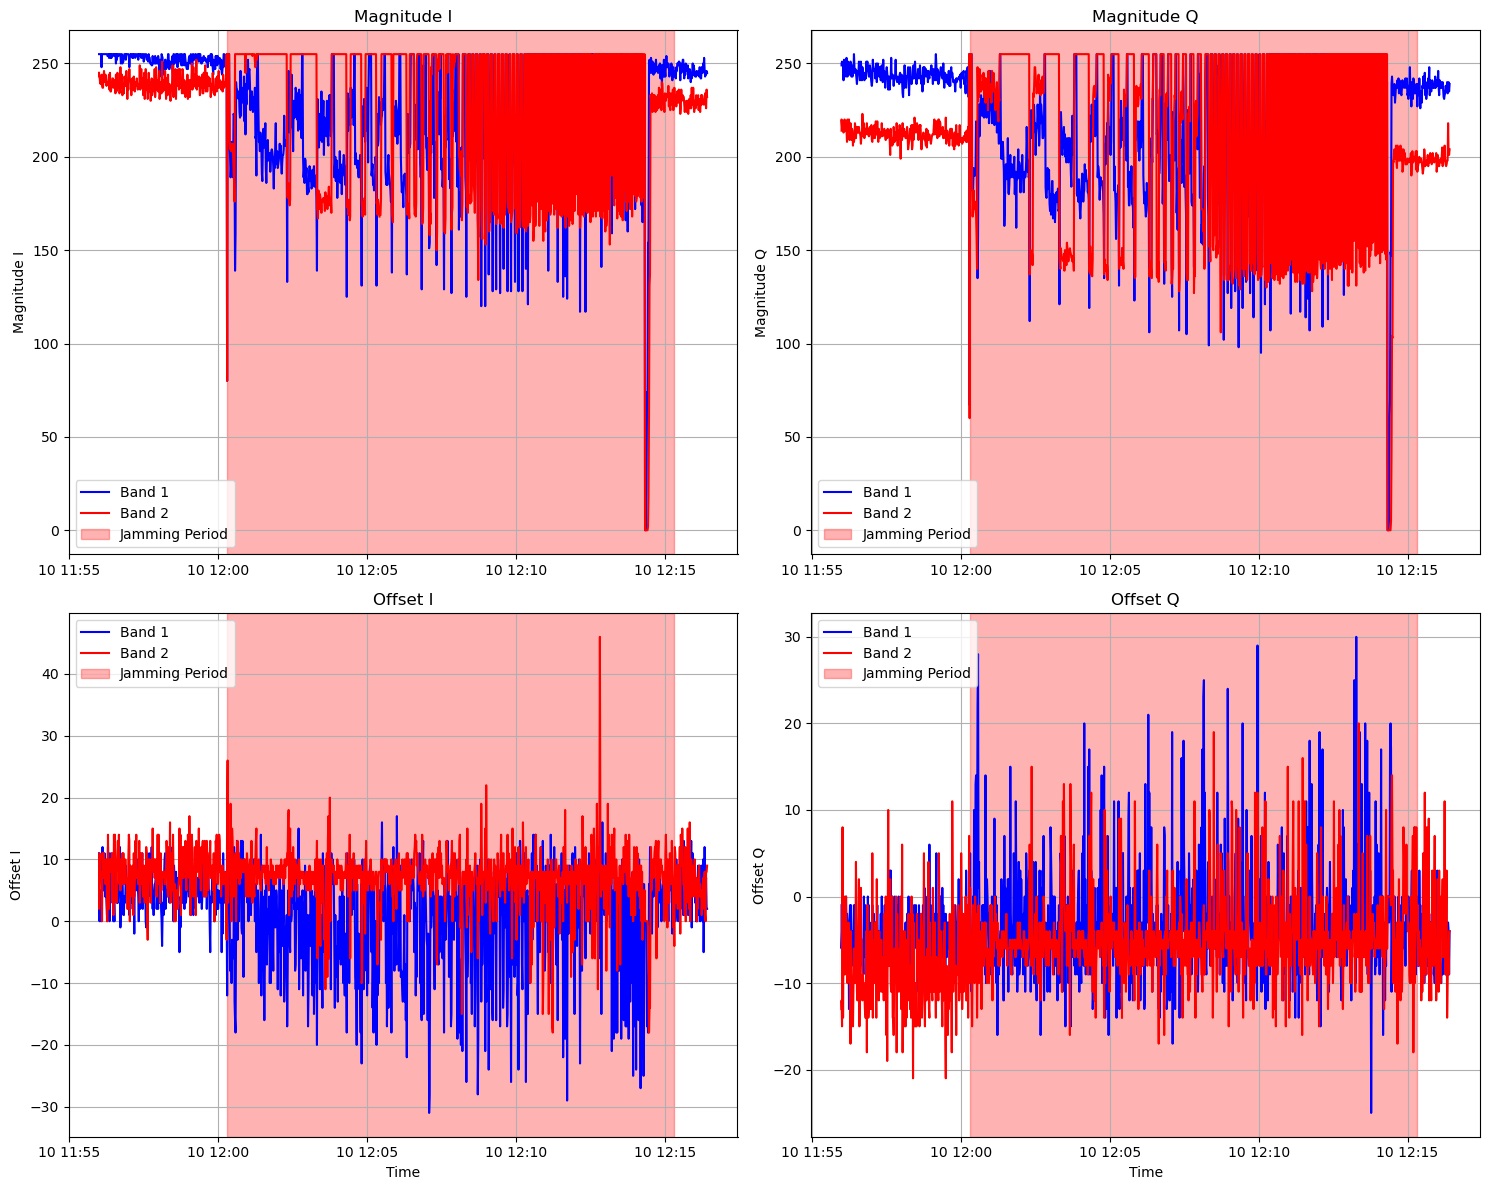

In [126]:
# Create figure with multiple subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

def plot_rf_metric(ax, df, col1, col2, title, ylabel):
    # Check if columns exist and contain valid data
    if col1 in df.columns and col2 in df.columns:
        ax.plot(df['real_time'], df[col1], label='Band 1', color='blue')
        ax.plot(df['real_time'], df[col2], label='Band 2', color='red')
        for start, end in adjusted_attack_periods:
            ax.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(True)
        ax.legend()
    else:
        ax.text(0.5, 0.5, f'No data available for {title}', 
                horizontalalignment='center', verticalalignment='center')

# Plot each RF metric
plot_rf_metric(ax1, mon_rf_data, 'magI_01', 'magI_02', 'Magnitude I', 'Magnitude I')
plot_rf_metric(ax2, mon_rf_data, 'magQ_01', 'magQ_02', 'Magnitude Q', 'Magnitude Q')
plot_rf_metric(ax3, mon_rf_data, 'ofsI_01', 'ofsI_02', 'Offset I', 'Offset I')
plot_rf_metric(ax4, mon_rf_data, 'ofsQ_01', 'ofsQ_02', 'Offset Q', 'Offset Q')

# Add x-labels to bottom plots
ax3.set_xlabel('Time')
ax4.set_xlabel('Time')

plt.tight_layout()
plt.show()


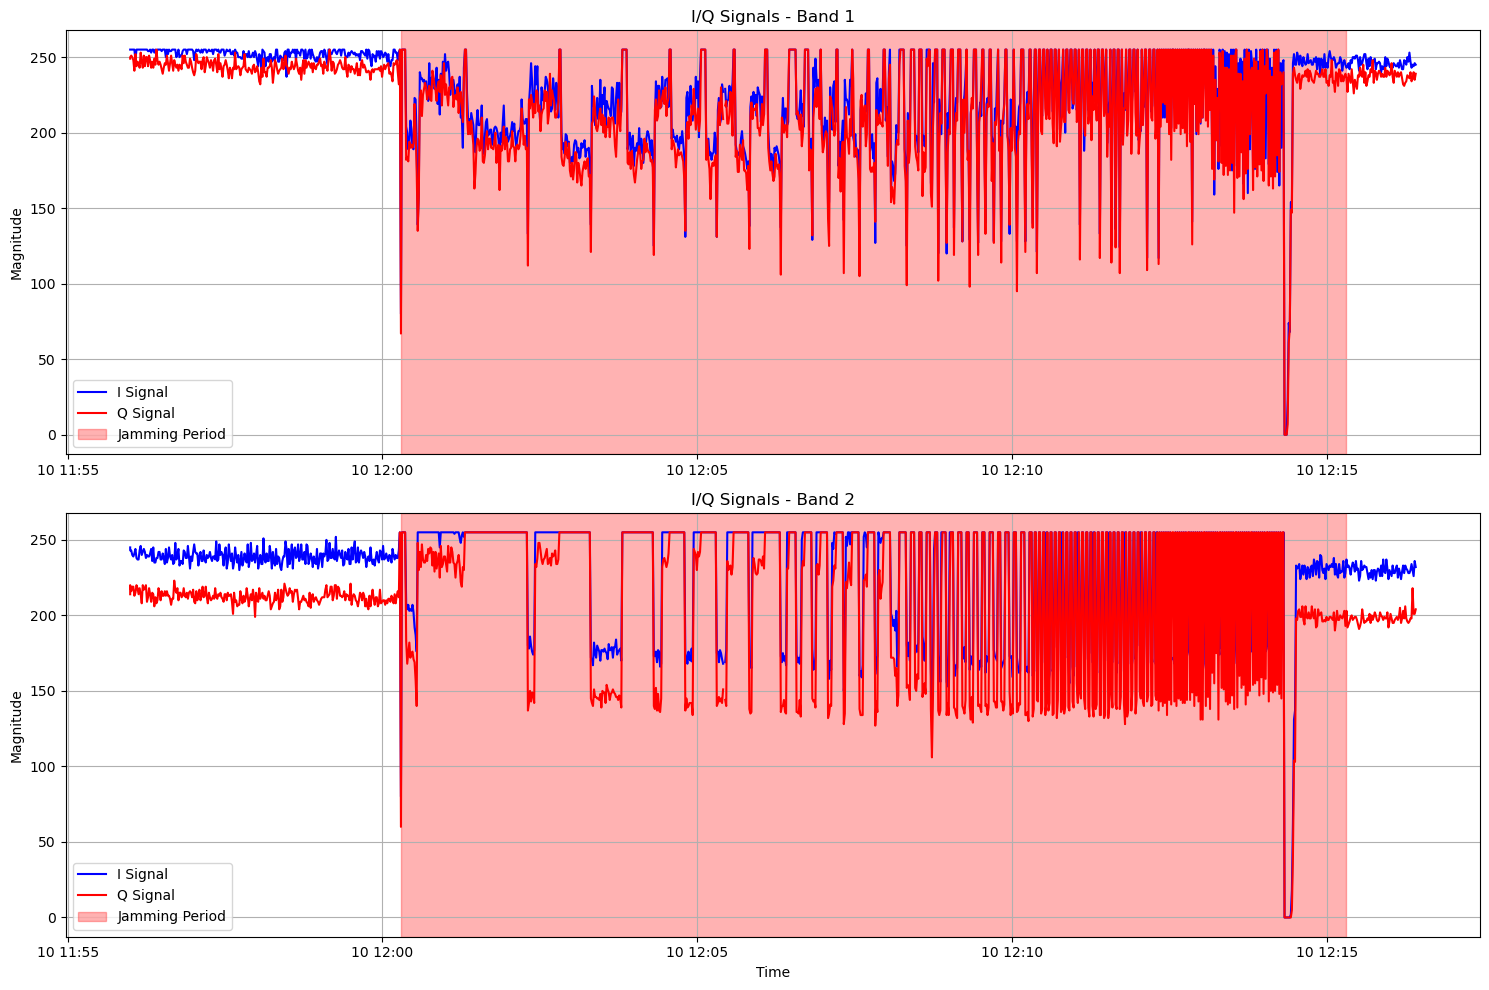

In [127]:
# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

# Plot I/Q signals for Band 1
ax1.plot(mon_rf_data['real_time'], mon_rf_data['magI_01'], label='I Signal', color='blue')
ax1.plot(mon_rf_data['real_time'], mon_rf_data['magQ_01'], label='Q Signal', color='red')
for start, end in adjusted_attack_periods:
    ax1.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax1.set_title('I/Q Signals - Band 1')
ax1.set_ylabel('Magnitude')
ax1.grid(True)
ax1.legend()

# Plot I/Q signals for Band 2
ax2.plot(mon_rf_data['real_time'], mon_rf_data['magI_02'], label='I Signal', color='blue')
ax2.plot(mon_rf_data['real_time'], mon_rf_data['magQ_02'], label='Q Signal', color='red')
for start, end in adjusted_attack_periods:
    ax2.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax2.set_title('I/Q Signals - Band 2')
ax2.set_xlabel('Time')
ax2.set_ylabel('Magnitude')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

## Mathematical Equations for Signal Magnitude Changes

For a time series signal $X(t)$ at time point $t$, the absolute difference is calculated as:

$\Delta|X(t)| = |X(t) - X(t-1)|$

Applied to each signal:

- I signal Band 1: $\Delta|I_1(t)| = |I_1(t) - I_1(t-1)|$
- Q signal Band 1: $\Delta|Q_1(t)| = |Q_1(t) - Q_1(t-1)|$
- I signal Band 2: $\Delta|I_2(t)| = |I_2(t) - I_2(t-1)|$
- Q signal Band 2: $\Delta|Q_2(t)| = |Q_2(t) - Q_2(t-1)|$

where:
- $I_1, Q_1$ represent the I/Q signals from Band 1
- $I_2, Q_2$ represent the I/Q signals from Band 2
- $t$ represents the current time point
- $t-1$ represents the previous time point

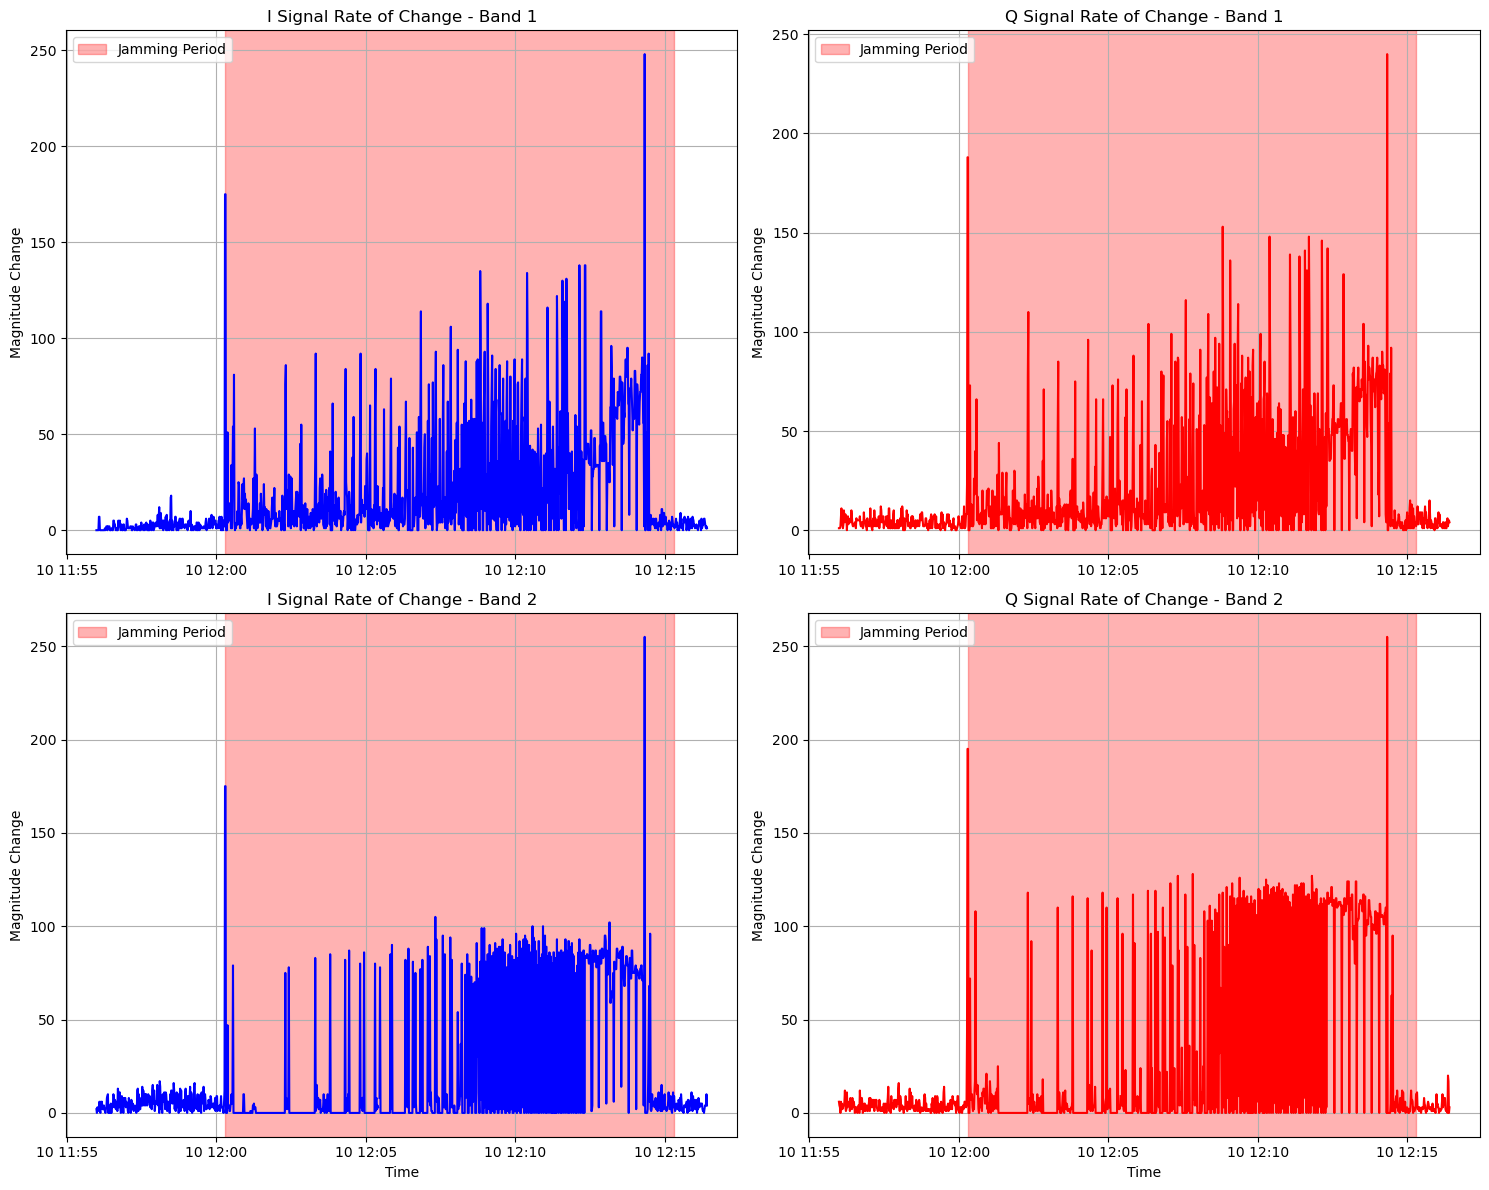

In [128]:
# Calculate the rate of change in I/Q signals
mon_rf_data['magI_01_diff'] = mon_rf_data['magI_01'].diff().abs()
mon_rf_data['magQ_01_diff'] = mon_rf_data['magQ_01'].diff().abs()
mon_rf_data['magI_02_diff'] = mon_rf_data['magI_02'].diff().abs()
mon_rf_data['magQ_02_diff'] = mon_rf_data['magQ_02'].diff().abs()
# Create figure with multiple subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Plot I signal differences for Band 1
ax1.plot(mon_rf_data['real_time'], mon_rf_data['magI_01_diff'], color='blue')
for start, end in adjusted_attack_periods:
    ax1.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax1.set_title('I Signal Rate of Change - Band 1')
ax1.set_ylabel('Magnitude Change')
ax1.grid(True)
ax1.legend()

# Plot Q signal differences for Band 1
ax2.plot(mon_rf_data['real_time'], mon_rf_data['magQ_01_diff'], color='red')
for start, end in adjusted_attack_periods:
    ax2.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax2.set_title('Q Signal Rate of Change - Band 1')
ax2.set_ylabel('Magnitude Change')
ax2.grid(True)
ax2.legend()

# Plot I signal differences for Band 2
ax3.plot(mon_rf_data['real_time'], mon_rf_data['magI_02_diff'], color='blue')
for start, end in adjusted_attack_periods:
    ax3.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax3.set_title('I Signal Rate of Change - Band 2')
ax3.set_xlabel('Time')
ax3.set_ylabel('Magnitude Change')
ax3.grid(True)
ax3.legend()

# Plot Q signal differences for Band 2
ax4.plot(mon_rf_data['real_time'], mon_rf_data['magQ_02_diff'], color='red')
for start, end in adjusted_attack_periods:
    ax4.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax4.set_title('Q Signal Rate of Change - Band 2')
ax4.set_xlabel('Time')
ax4.set_ylabel('Magnitude Change')
ax4.grid(True)
ax4.legend()

plt.tight_layout()
plt.show()

In [129]:
# import folium
# from folium.plugins import HeatMap, TimestampedGeoJson

# # First, make sure time is in datetime format
# nav_pvt_data['real_time'] = pd.to_datetime(nav_pvt_data['real_time'])

# # Check if coordinates need scaling - typical GPS coordinates should be between -90 to 90 for lat and -180 to 180 for lon
# # If values are too small, they might need scaling (e.g. if they're in radians or another unit)
# if abs(nav_pvt_data['lat'].mean()) < 0.001 and abs(nav_pvt_data['lon'].mean()) < 0.001:
#     # Apply scaling factor - assuming these might be in radians or need conversion
#     # Common conversion is 180/pi for radians to degrees
#     scale_factor = 1e7  # Adjust based on data examination
#     nav_pvt_data['map_lat'] = nav_pvt_data['lat'] * scale_factor
#     nav_pvt_data['map_lon'] = nav_pvt_data['lon'] * scale_factor
# else:
#     nav_pvt_data['map_lat'] = nav_pvt_data['lat']
#     nav_pvt_data['map_lon'] = nav_pvt_data['lon']

# # Calculate the center of the map using scaled coordinates
# center_lat = nav_pvt_data['map_lat'].mean()
# center_lon = nav_pvt_data['map_lon'].mean()

# # Create the map with error handling for invalid coordinates
# if -90 <= center_lat <= 90 and -180 <= center_lon <= 180:
#     m = folium.Map(location=[center_lat, center_lon], zoom_start=15)
# else:
#     # Fallback to a default location if coordinates are invalid
#     m = folium.Map(location=[0, 0], zoom_start=2)
#     folium.Marker(
#         [0, 0],
#         popup='Warning: Invalid GPS coordinates detected',
#         icon=folium.Icon(color='red', icon='warning-sign')
#     ).add_to(m)

# # Add the GPS track as a line using scaled coordinates (showing entire track with one color)
# if not nav_pvt_data.empty:
#     folium.PolyLine(
#         list(zip(nav_pvt_data['map_lat'], nav_pvt_data['map_lon'])),
#         color='blue',
#         weight=3,
#         tooltip='GPS Track'
#     ).add_to(m)

# # Add markers for start and end points using scaled coordinates
# if not nav_pvt_data.empty:
#     folium.Marker(
#         [nav_pvt_data['map_lat'].iloc[0], nav_pvt_data['map_lon'].iloc[0]],
#         popup=f'Start: {nav_pvt_data["real_time"].iloc[0]}',
#         icon=folium.Icon(color='green', icon='play')
#     ).add_to(m)

#     folium.Marker(
#         [nav_pvt_data['map_lat'].iloc[-1], nav_pvt_data['map_lon'].iloc[-1]],
#         popup=f'End: {nav_pvt_data["real_time"].iloc[-1]}',
#         icon=folium.Icon(color='red', icon='stop')
#     ).add_to(m)

# # Add a simplified legend
# legend_html = '''
# <div style="position: fixed; 
#     bottom: 50px; left: 50px; width: 150px; height: 80px; 
#     background-color: white; border:2px solid grey; z-index:9999; font-size:14px;
#     padding: 10px">
#     <p><b>Legend:</b></p>
#     <p><i class="fa fa-circle" style="color:blue"></i> GPS Track</p>
# </div>
# '''
# m.get_root().html.add_child(folium.Element(legend_html))

# # Add a note about coordinate scaling
# if abs(nav_pvt_data['lat'].mean()) < 0.001:
#     scaling_note = f'''
#     <div style="position: fixed; 
#         top: 10px; right: 10px; width: 200px; 
#         background-color: white; border:2px solid grey; z-index:9999; font-size:12px;
#         padding: 10px">
#         <p><b>Note:</b> Coordinates were scaled by {scale_factor}x for visualization.</p>
#     </div>
#     '''
#     m.get_root().html.add_child(folium.Element(scaling_note))

# m


Available columns: ['timestamp', 'identity', 'iTOW', 'satellite', 'real_time', 'day', 'fixType', 'flags', 'gSpeed', 'gnssId', 'hAcc', 'hMSL', 'headAcc', 'headMot', 'headVeh', 'height', 'hour', 'lat', 'lon', 'magAcc', 'magDec', 'min', 'month', 'numSV', 'pDOP', 'sAcc', 'sec', 'svId', 'tAcc', 'vAcc', 'velD', 'velE', 'velN', 'year']
Points during jamming: 900 of 1226
Using longitude column: lon
Using latitude column: lat


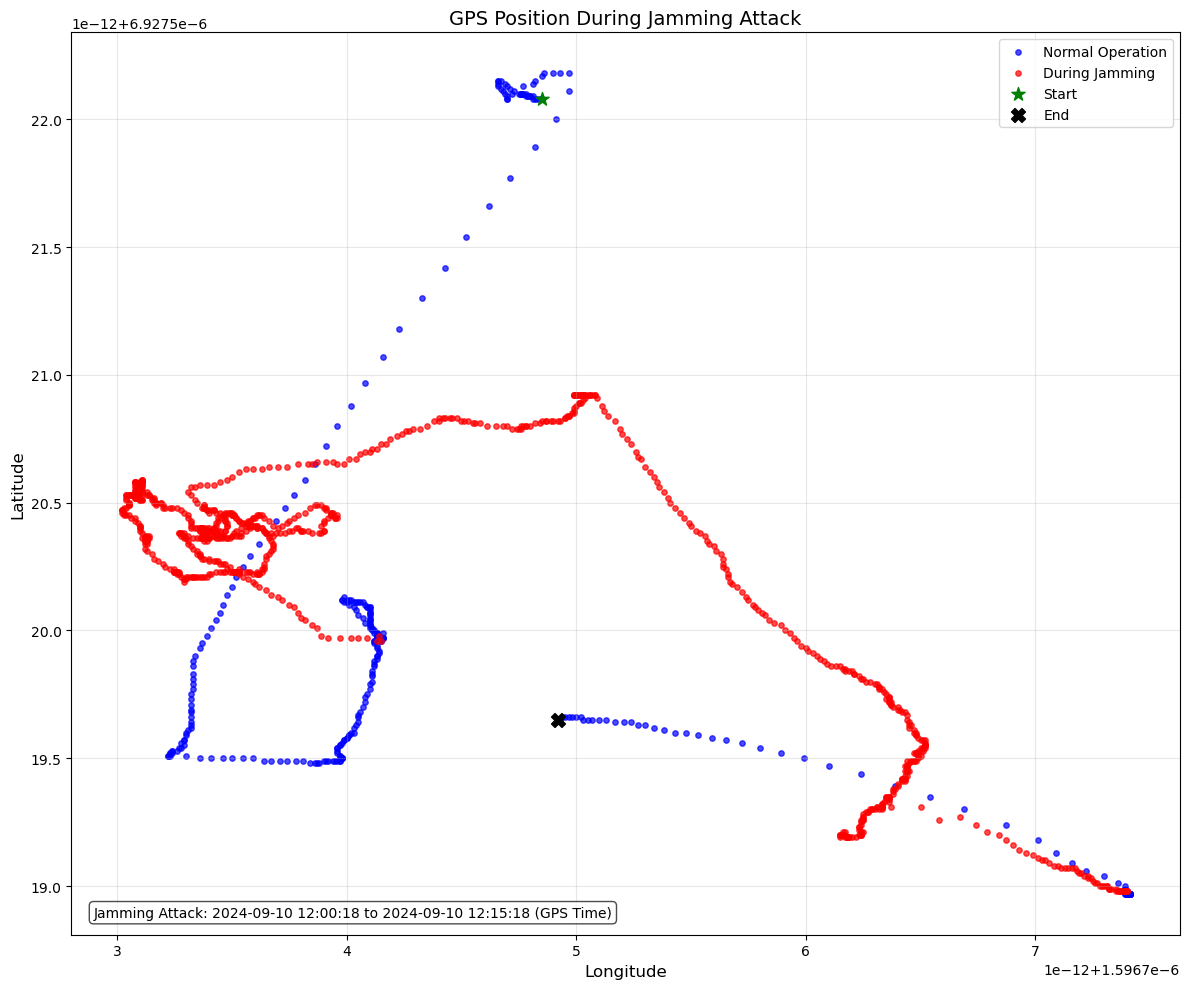

In [130]:
# Create a scatter plot of position data
plt.figure(figsize=(12, 10))

import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# First, let's check what columns are actually available
print(f"Available columns: {nav_pvt_data.columns.tolist()}")

# Convert string timestamps to datetime objects if needed
if nav_pvt_data['real_time'].dtype == 'object':  # If it's a string
    nav_pvt_data['real_time'] = pd.to_datetime(nav_pvt_data['real_time'])

# Define attack timeframe (as GPS time)
attack_start_str
attack_end_str 

# Convert string attack times to datetime objects (same format as in DataFrame)
attack_start = pd.to_datetime(attack_start_str)
attack_end = pd.to_datetime(attack_end_str)

# GPS time doesn't have timezone info, so ensure all datetime objects are naive
if hasattr(attack_start, 'tzinfo') and attack_start.tzinfo is not None:
    attack_start = attack_start.tz_localize(None)
if hasattr(attack_end, 'tzinfo') and attack_end.tzinfo is not None:
    attack_end = attack_end.tz_localize(None)

# If DataFrame times have timezone info, remove it
if pd.notnull(nav_pvt_data['real_time'].iloc[0]) and hasattr(nav_pvt_data['real_time'].iloc[0], 'tzinfo') and nav_pvt_data['real_time'].iloc[0].tzinfo is not None:
    nav_pvt_data['real_time'] = nav_pvt_data['real_time'].dt.tz_localize(None)


# Create a mask to identify points during jamming periods
jamming_mask = pd.Series(False, index=nav_pvt_data.index)
for start, end in adjusted_attack_periods:
    # Mark points that fall within this attack period
    start=start.strftime('%Y-%m-%d %H:%M:%S')
    end=end.strftime('%Y-%m-%d %H:%M:%S')
    period_mask = (nav_pvt_data['real_time'] >= start) & (nav_pvt_data['real_time'] <= end)
    jamming_mask = jamming_mask | period_mask

print(f"Points during jamming: {jamming_mask.sum()} of {len(jamming_mask)}")

# Find longitude and latitude column names
# Common options for longitude: lon, long, longitude, map_lon, etc.
# Common options for latitude: lat, latitude, map_lat, etc.
lon_options = ['lon', 'long', 'longitude', 'map_lon', 'lng', 'LON', 'Longitude', 'LONGITUDE']
lat_options = ['lat', 'latitude', 'map_lat', 'LAT', 'Latitude', 'LATITUDE']

lon_col = None
lat_col = None

for col in lon_options:
    if col in nav_pvt_data.columns:
        lon_col = col
        break

for col in lat_options:
    if col in nav_pvt_data.columns:
        lat_col = col
        break

if lon_col is None or lat_col is None:
    raise ValueError(f"Could not find longitude/latitude columns. Available columns: {nav_pvt_data.columns.tolist()}")

print(f"Using longitude column: {lon_col}")
print(f"Using latitude column: {lat_col}")

# Plot points before/after jamming in blue
plt.scatter(nav_pvt_data.loc[~jamming_mask, lon_col], 
            nav_pvt_data.loc[~jamming_mask, lat_col], 
            c='blue', alpha=0.7, s=15, label='Normal Operation')

# Plot points during jamming in red
plt.scatter(nav_pvt_data.loc[jamming_mask, lon_col], 
            nav_pvt_data.loc[jamming_mask, lat_col], 
            c='red', alpha=0.7, s=15, label='During Jamming')

# Mark start and end points
plt.scatter(nav_pvt_data[lon_col].iloc[0], nav_pvt_data[lat_col].iloc[0], 
            c='green', s=100, marker='*', label='Start')
plt.scatter(nav_pvt_data[lon_col].iloc[-1], nav_pvt_data[lat_col].iloc[-1], 
            c='black', s=100, marker='X', label='End')

# Add labels and legend
plt.title('GPS Position During Jamming Attack', fontsize=14)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='best', fontsize=10)

# Add annotation with attack details
attack_info = f"Jamming Attack: {attack_start_str} to {attack_end_str} (GPS Time)"
plt.annotate(attack_info, 
             xy=(0.02, 0.02), xycoords='axes fraction', 
             fontsize=10, bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7))

plt.tight_layout()
plt.show()

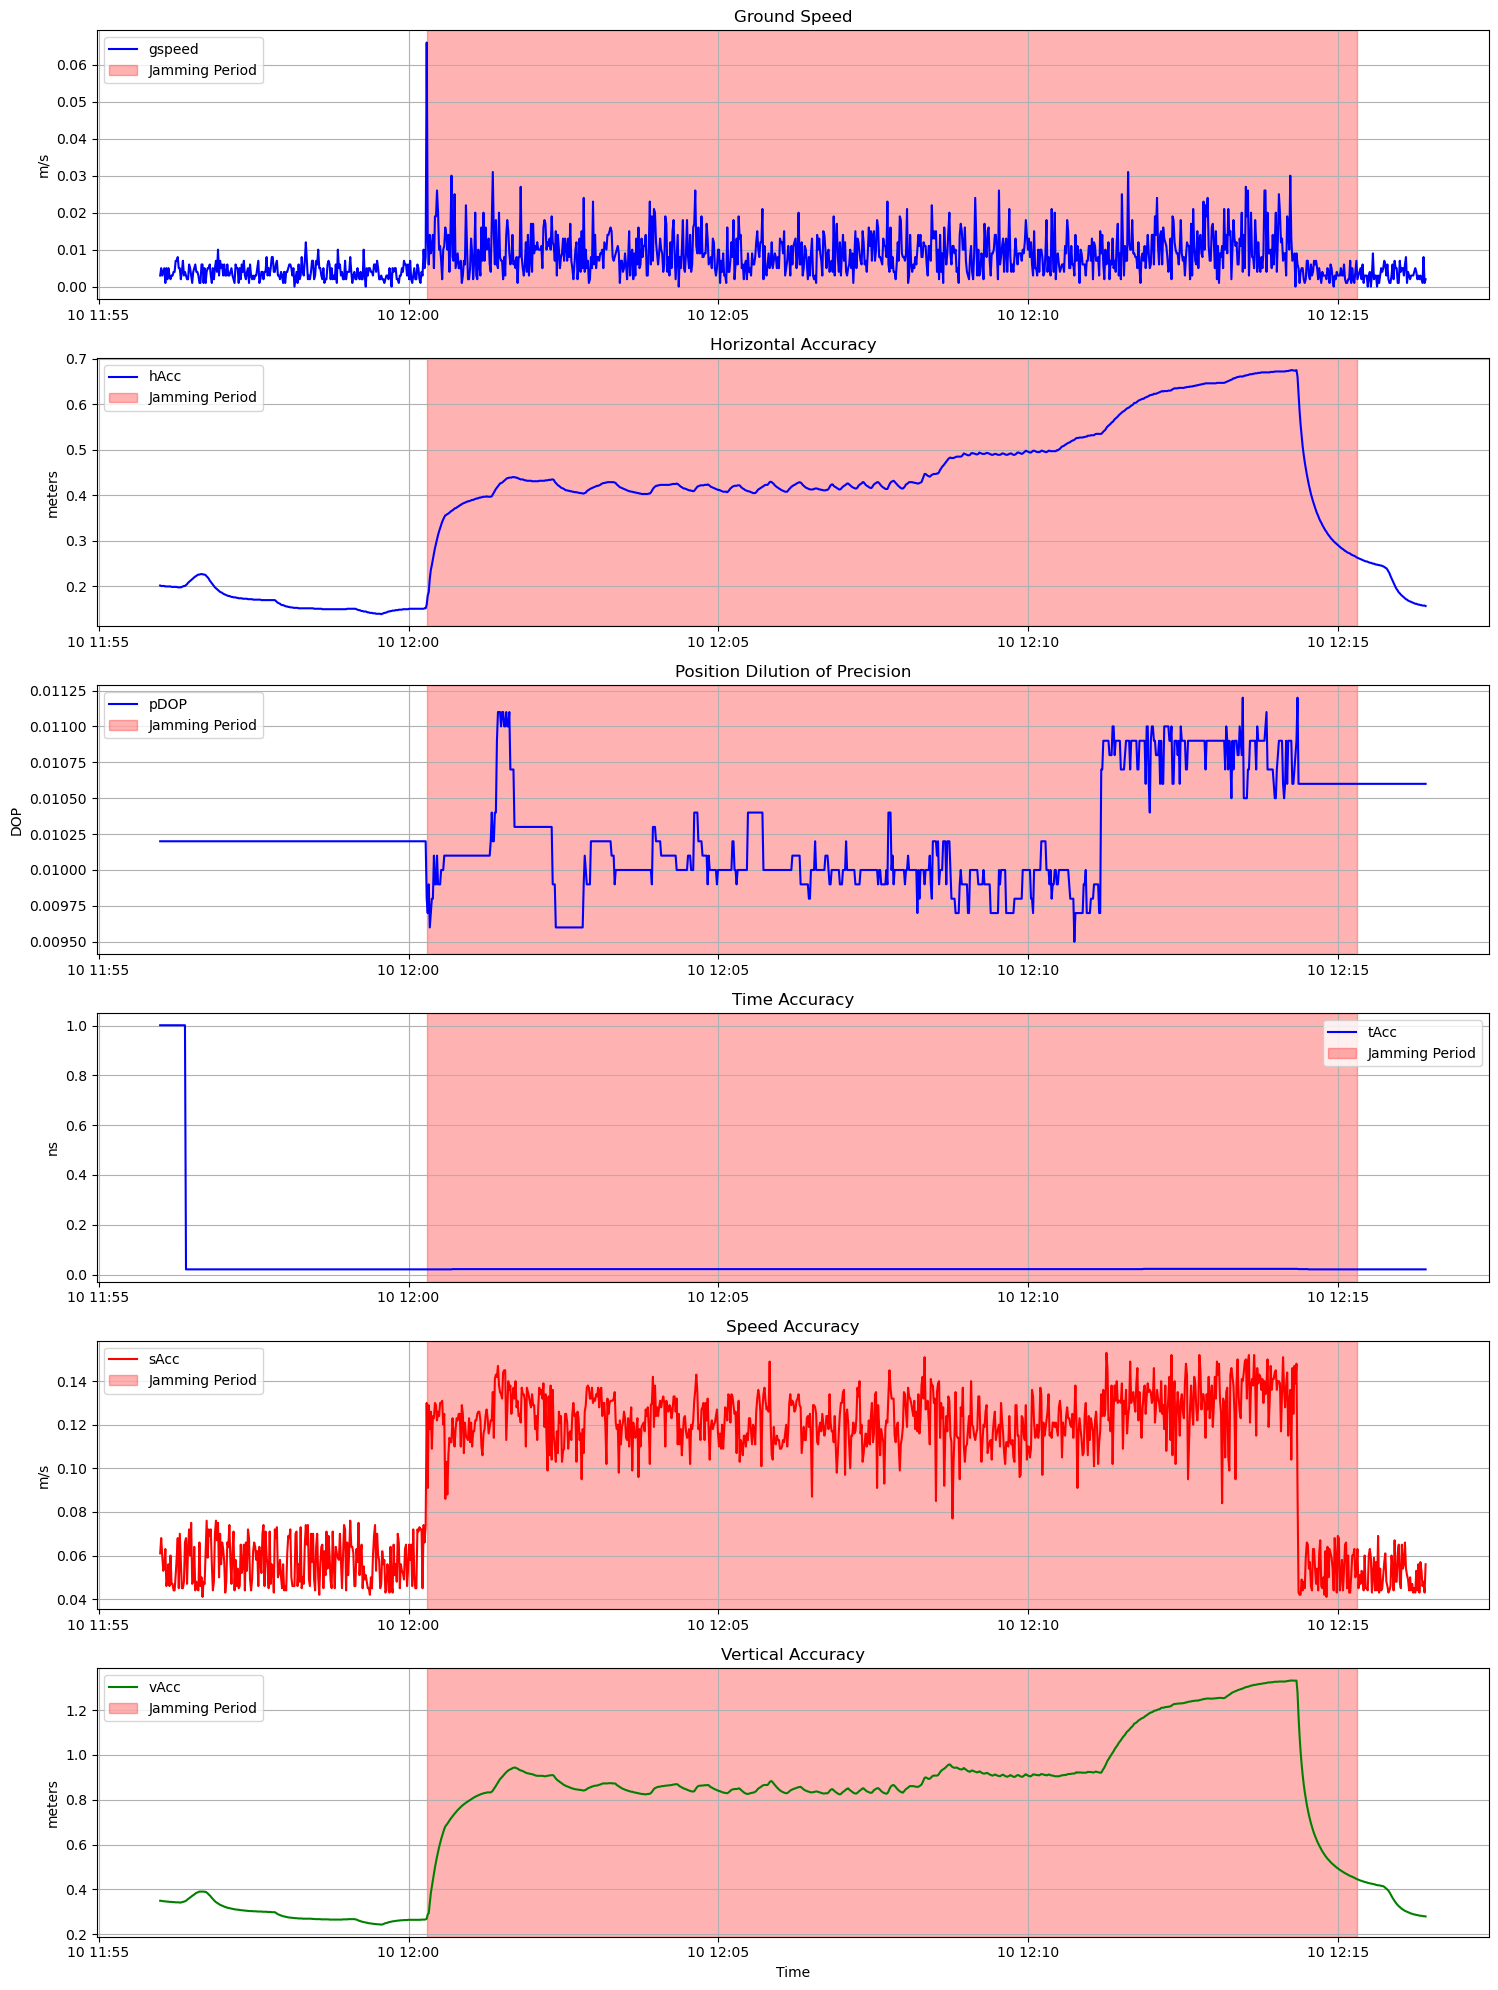

In [131]:
# Create figure with two subplots
fig, (ax1, ax2, ax3, ax4, ax5, ax6) = plt.subplots(6, 1, figsize=(15, 20))

# Plot gSpeed
ax1.plot(nav_pvt_data['real_time'], nav_pvt_data['gSpeed'], label='gspeed', color='blue')
for start, end in adjusted_attack_periods:
    ax1.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax1.set_title('Ground Speed')
ax1.set_ylabel('m/s')
ax1.grid(True)
ax1.legend()

# Plot hAcc
ax2.plot(nav_pvt_data['real_time'], nav_pvt_data['hAcc'], label='hAcc', color='blue')
for start, end in adjusted_attack_periods:
    ax2.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax2.set_title('Horizontal Accuracy')
ax2.set_ylabel('meters')
ax2.grid(True)
ax2.legend()

# Plot pDOP
ax3.plot(nav_pvt_data['real_time'], nav_pvt_data['pDOP'], label='pDOP', color='blue')
for start, end in adjusted_attack_periods:
    ax3.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax3.set_title('Position Dilution of Precision')
ax3.set_ylabel('DOP')
ax3.grid(True)
ax3.legend()

# Plot tAcc
ax4.plot(nav_pvt_data['real_time'], nav_pvt_data['tAcc'], label='tAcc', color='blue')
for start, end in adjusted_attack_periods:
    ax4.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax4.set_title('Time Accuracy')
ax4.set_ylabel('ns')
ax4.grid(True)
ax4.legend()

# Plot sAcc
ax5.plot(nav_pvt_data['real_time'], nav_pvt_data['sAcc'], label='sAcc', color='red')
for start, end in adjusted_attack_periods:
    ax5.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax5.set_title('Speed Accuracy')
ax5.set_ylabel('m/s')
ax5.grid(True)
ax5.legend()

# Plot vAcc
ax6.plot(nav_pvt_data['real_time'], nav_pvt_data['vAcc'], label='vAcc', color='green')
for start, end in adjusted_attack_periods:
    ax6.axvspan(start, end, color='red', alpha=0.3, label='Jamming Period')
ax6.set_title('Vertical Accuracy')
ax6.set_xlabel('Time')
ax6.set_ylabel('meters')
ax6.grid(True)
ax6.legend()

plt.tight_layout()
plt.show()

In [132]:
import folium
from folium.plugins import HeatMap, TimestampedGeoJson

# First, make sure time is in datetime format
nav_pvt_data['real_time'] = pd.to_datetime(nav_pvt_data['real_time'])

# Check if coordinates need scaling - typical GPS coordinates should be between -90 to 90 for lat and -180 to 180 for lon
# If values are too small, they might need scaling (e.g. if they're in radians or another unit)
if abs(nav_pvt_data['lat'].mean()) < 0.001 and abs(nav_pvt_data['lon'].mean()) < 0.001:
    # Apply scaling factor - assuming these might be in radians or need conversion
    # Common conversion is 180/pi for radians to degrees
    scale_factor = 1e7  # Adjust based on data examination
    nav_pvt_data['map_lat'] = nav_pvt_data['lat'] * scale_factor
    nav_pvt_data['map_lon'] = nav_pvt_data['lon'] * scale_factor
else:
    nav_pvt_data['map_lat'] = nav_pvt_data['lat'] 
    nav_pvt_data['map_lon'] = nav_pvt_data['lon']



# Convert to datetime objects
attack_start = pd.to_datetime(attack_start_str)
attack_end = pd.to_datetime(attack_end_str)

# Make sure all datetime objects are in the same format (naive)
if attack_start.tzinfo is not None:
    attack_start = attack_start.tz_localize(None)
if attack_end.tzinfo is not None:
    attack_end = attack_end.tz_localize(None)
    
if pd.notnull(nav_pvt_data['real_time'].iloc[0]) and hasattr(nav_pvt_data['real_time'].iloc[0], 'tzinfo') and nav_pvt_data['real_time'].iloc[0].tzinfo is not None:
    nav_pvt_data['real_time'] = nav_pvt_data['real_time'].dt.tz_localize(None)

# Create mask for jamming period
# WITH this code:
def create_jamming_mask(df, attack_periods, time_column='real_time'):
    """Create a boolean mask that's True during any attack period."""
    mask = pd.Series(False, index=df.index)
    for start, end in attack_periods:
        period_mask = (df[time_column] >= start) & (df[time_column] <= end)
        mask = mask | period_mask
    return mask



# Calculate the center of the map using scaled coordinates
center_lat = nav_pvt_data['map_lat'].mean()
center_lon = nav_pvt_data['map_lon'].mean()

# Create the map with error handling for invalid coordinates
if -90 <= center_lat <= 90 and -180 <= center_lon <= 180:
    m = folium.Map(location=[center_lat, center_lon], zoom_start=15)
else:
    # Fallback to a default location if coordinates are invalid
    print(f"Warning: Unusual coordinates detected - center_lat: {center_lat}, center_lon: {center_lon}")
    # Try to find some valid points to center on
    valid_points = nav_pvt_data[(nav_pvt_data['map_lat'].between(-90, 90)) & 
                               (nav_pvt_data['map_lon'].between(-180, 180))]
    if not valid_points.empty:
        print("Using valid points for map center")
        center_lat = valid_points['map_lat'].mean()
        center_lon = valid_points['map_lon'].mean()
        m = folium.Map(location=[center_lat, center_lon], zoom_start=15)
    else:
        m = folium.Map(location=[0, 0], zoom_start=2)
        folium.Marker(
            [0, 0],
            popup='Warning: Invalid GPS coordinates detected',
            icon=folium.Icon(color='red', icon='warning-sign')
        ).add_to(m)

# Create feature groups for normal operation and jamming
normal_fg = folium.FeatureGroup(name="Normal Operation")
jamming_fg = folium.FeatureGroup(name="Jamming Period")

# Add normal operation points (blue)
for idx, row in nav_pvt_data[~jamming_mask].iterrows():
    folium.CircleMarker(
        location=[row['map_lat'], row['map_lon']],
        radius=3,
        color='blue',
        fill=True,
        popup=f"Time: {row['real_time']}",
        opacity=0.7
    ).add_to(normal_fg)

# Add jamming points (red)
for idx, row in nav_pvt_data[jamming_mask].iterrows():
    folium.CircleMarker(
        location=[row['map_lat'], row['map_lon']],
        radius=3,
        color='red',
        fill=True,
        popup=f"Time: {row['real_time']}",
        opacity=0.7
    ).add_to(jamming_fg)

# Add the feature groups to the map
normal_fg.add_to(m)
jamming_fg.add_to(m)

# Add the GPS track as a line
if not nav_pvt_data.empty:
    folium.PolyLine(
        list(zip(nav_pvt_data['map_lat'], nav_pvt_data['map_lon'])),
        color='gray',
        weight=1.5,
        opacity=0.5,
        tooltip='GPS Track'
    ).add_to(m)

# Add markers for start and end points
if not nav_pvt_data.empty:
    folium.Marker(
        [nav_pvt_data['map_lat'].iloc[0], nav_pvt_data['map_lon'].iloc[0]],
        popup=f'Start: {nav_pvt_data["real_time"].iloc[0]}',
        icon=folium.Icon(color='green', icon='play')
    ).add_to(m)

    folium.Marker(
        [nav_pvt_data['map_lat'].iloc[-1], nav_pvt_data['map_lon'].iloc[-1]],
        popup=f'End: {nav_pvt_data["real_time"].iloc[-1]}',
        icon=folium.Icon(color='black', icon='stop')
    ).add_to(m)

# Add a more detailed legend
legend_html = '''
<div style="position: fixed; 
    bottom: 50px; left: 50px; width: 200px; height: 130px; 
    background-color: white; border:2px solid grey; z-index:9999; font-size:14px;
    padding: 10px">
    <p><b>Legend:</b></p>
    <p><i class="fa fa-circle" style="color:blue"></i> Normal Operation</p>
    <p><i class="fa fa-circle" style="color:red"></i> During Jamming</p>
    <p><i class="fa fa-play" style="color:green"></i> Start Point</p>
    <p><i class="fa fa-stop" style="color:black"></i> End Point</p>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# Add a note about coordinate scaling and attack details
info_html = f'''
<div style="position: fixed; 
    top: 10px; right: 10px; width: 220px; 
    background-color: white; border:2px solid grey; z-index:9999; font-size:12px;
    padding: 10px">
    <p><b>Jamming Attack:</b></p>
    <p>Start: {attack_start_str}</p>
    <p>End: {attack_end_str}</p>
    <p>Duration: {attack_end - attack_start}</p>
    {'<p><b>Note:</b> Coordinates scaled by '+str(scale_factor)+'x</p>' if abs(nav_pvt_data['lat'].mean()) < 0.001 else ''}
</div>
'''
m.get_root().html.add_child(folium.Element(info_html))

# Add layer control for toggling feature groups
folium.LayerControl().add_to(m)

m

In [133]:
import folium
from folium.plugins import TimestampedGeoJson, MeasureControl
import pandas as pd
import json
from datetime import timedelta

# First, make sure time is in datetime format
nav_pvt_data['real_time'] = pd.to_datetime(nav_pvt_data['real_time'])

# Check if coordinates need scaling - typical GPS coordinates should be between -90 to 90 for lat and -180 to 180 for lon
if abs(nav_pvt_data['lat'].mean()) < 0.001 and abs(nav_pvt_data['lon'].mean()) < 0.001:
    scale_factor = 1e7  # Adjust based on data examination
    nav_pvt_data['map_lat'] = nav_pvt_data['lat'] * scale_factor
    nav_pvt_data['map_lon'] = nav_pvt_data['lon'] * scale_factor
else:
    nav_pvt_data['map_lat'] = nav_pvt_data['lat'] 
    nav_pvt_data['map_lon'] = nav_pvt_data['lon']

# Extract attack period from scenario_info if available
attack_start_str = "2024-09-10 06:59:42"  # Default from info_html
attack_end_str = "2024-09-10 07:05:42"    # Default from info_html

# If scenario_info is available, use the attack log details
if 'scenario_info' in locals() and 'attack_log' in scenario_info:
    attack_periods = []
    for attack in scenario_info['attack_log']:
        if 'start_time' in attack and 'end_time' in attack:
            attack_periods.append({
                'start': pd.to_datetime(attack['start_time']),
                'end': pd.to_datetime(attack['end_time'])
            })

# Convert to datetime objects
attack_start = pd.to_datetime(attack_start_str)
attack_end = pd.to_datetime(attack_end_str)

# Make sure all datetime objects are in the same format (naive)
if attack_start.tzinfo is not None:
    attack_start = attack_start.tz_localize(None)
if attack_end.tzinfo is not None:
    attack_end = attack_end.tz_localize(None)
    
if pd.notnull(nav_pvt_data['real_time'].iloc[0]) and hasattr(nav_pvt_data['real_time'].iloc[0], 'tzinfo') and nav_pvt_data['real_time'].iloc[0].tzinfo is not None:
    nav_pvt_data['real_time'] = nav_pvt_data['real_time'].dt.tz_localize(None)

# Calculate the center of the map using scaled coordinates
center_lat = nav_pvt_data['map_lat'].mean()
center_lon = nav_pvt_data['map_lon'].mean()

# Create the map with error handling for invalid coordinates
if -90 <= center_lat <= 90 and -180 <= center_lon <= 180:
    m = folium.Map(location=[center_lat, center_lon], zoom_start=15)
else:
    print(f"Warning: Unusual coordinates detected - center_lat: {center_lat}, center_lon: {center_lon}")
    valid_points = nav_pvt_data[(nav_pvt_data['map_lat'].between(-90, 90)) & 
                              (nav_pvt_data['map_lon'].between(-180, 180))]
    if not valid_points.empty:
        print("Using valid points for map center")
        center_lat = valid_points['map_lat'].mean()
        center_lon = valid_points['map_lon'].mean()
        m = folium.Map(location=[center_lat, center_lon], zoom_start=15)
    else:
        m = folium.Map(location=[0, 0], zoom_start=2)
        folium.Marker(
            [0, 0],
            popup='Warning: Invalid GPS coordinates detected',
            icon=folium.Icon(color='red', icon='warning-sign')
        ).add_to(m)

# Create base feature groups for static elements
static_fg = folium.FeatureGroup(name="Static Elements")
jamming_fg = folium.FeatureGroup(name="Jamming Period")

# Add the complete GPS track as a gray line
if not nav_pvt_data.empty:
    folium.PolyLine(
        list(zip(nav_pvt_data['map_lat'], nav_pvt_data['map_lon'])),
        color='gray',
        weight=1.5,
        opacity=0.5,
        tooltip='Complete GPS Track'
    ).add_to(static_fg)

# Add start and end markers
folium.Marker(
    [nav_pvt_data['map_lat'].iloc[0], nav_pvt_data['map_lon'].iloc[0]],
    popup=f'Start: {nav_pvt_data["real_time"].iloc[0]}',
    icon=folium.Icon(color='green', icon='play')
).add_to(static_fg)

folium.Marker(
    [nav_pvt_data['map_lat'].iloc[-1], nav_pvt_data['map_lon'].iloc[-1]],
    popup=f'End: {nav_pvt_data["real_time"].iloc[-1]}',
    icon=folium.Icon(color='black', icon='stop')
).add_to(static_fg)


if jamming_mask.any():
    # Add a path for the jamming period
    jamming_track = nav_pvt_data[jamming_mask]
    folium.PolyLine(
        list(zip(jamming_track['map_lat'], jamming_track['map_lon'])),
        color='red',
        weight=3,
        opacity=0.8,
        tooltip='Jamming Period'
    ).add_to(jamming_fg)
    
    # Add markers at start and end of jamming
    folium.Marker(
        [jamming_track['map_lat'].iloc[0], jamming_track['map_lon'].iloc[0]],
        popup=f'Jamming Start: {jamming_track["real_time"].iloc[0]}',
        icon=folium.Icon(color='red', icon='warning-sign')
    ).add_to(jamming_fg)
    
    folium.Marker(
        [jamming_track['map_lat'].iloc[-1], jamming_track['map_lon'].iloc[-1]],
        popup=f'Jamming End: {jamming_track["real_time"].iloc[-1]}',
        icon=folium.Icon(color='orange', icon='warning-sign')
    ).add_to(jamming_fg)

# Add feature groups to the map
static_fg.add_to(m)
jamming_fg.add_to(m)

# Create an alternative visualization using TimestampedGeoJson
# Create a new DataFrame to hold position at each time point
times = sorted(nav_pvt_data['real_time'].unique())
positions = []

# Create a list of positions over time
for t in times:
    point_data = nav_pvt_data[nav_pvt_data['real_time'] == t].iloc[0]
    is_jamming = attack_start <= t <= attack_end
    positions.append({
        'time': t.strftime('%Y-%m-%d %H:%M:%S'),  # Format time as string
        'lat': point_data['map_lat'],
        'lon': point_data['map_lon'],
        'is_jamming': is_jamming
    })

# Prepare data for TimestampedGeoJson
features = []

# Create features for each position
for i, pos in enumerate(positions):
    point_feature = {
        'type': 'Feature',
        'geometry': {
            'type': 'Point',
            'coordinates': [pos['lon'], pos['lat']]
        },
        'properties': {
            'time': pos['time'],
            'icon': 'circle',
            'iconstyle': {
                'fillColor': 'red' if pos['is_jamming'] else 'blue',
                'fillOpacity': 0.8 if pos['is_jamming'] else 0.6,
                'stroke': 'true',
                'radius': 8 if pos['is_jamming'] else 5
            },
            'popup': f"Time: {pos['time']}<br>{'JAMMING ACTIVE' if pos['is_jamming'] else 'Normal Operation'}"
        }
    }
    features.append(point_feature)
    
    # Add path segments
    if i > 0:
        prev_pos = positions[i-1]
        path_feature = {
            'type': 'Feature',
            'geometry': {
                'type': 'LineString',
                'coordinates': [
                    [prev_pos['lon'], prev_pos['lat']],
                    [pos['lon'], pos['lat']]
                ]
            },
            'properties': {
                'time': pos['time'],
                'style': {
                    'color': 'red' if pos['is_jamming'] else 'blue',
                    'weight': 3 if pos['is_jamming'] else 1.5
                }
            }
        }
        features.append(path_feature)

# Create TimestampedGeoJson with simpler time format
timestamped = TimestampedGeoJson(
    {'type': 'FeatureCollection',
     'features': features},
    period='PT1S',
    add_last_point=True,
    auto_play=True,
    loop=False,
    max_speed=100,
    loop_button=True,
    date_options='YYYY/MM/DD HH:mm:ss',
    time_slider_drag_update=True,
    duration='PT1S'
)

timestamped.add_to(m)

# Add measurement tool
MeasureControl(position='topleft', primary_length_unit='meters').add_to(m)

# Add a legend
legend_html = '''
<div style="position: fixed; 
    bottom: 50px; left: 50px; width: 200px; 
    background-color: white; border:2px solid grey; z-index:9999; font-size:14px;
    padding: 10px">
    <p><b>Legend:</b></p>
    <p><i class="fa fa-circle" style="color:blue"></i> Normal Operation</p>
    <p><i class="fa fa-circle" style="color:red"></i> During Jamming</p>
    <p><i class="fa fa-play" style="color:green"></i> Start Point</p>
    <p><i class="fa fa-stop" style="color:black"></i> End Point</p>
    <p><i class="fa fa-warning-sign" style="color:red"></i> Jamming Start</p>
    <p><i class="fa fa-warning-sign" style="color:orange"></i> Jamming End</p>
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# Add attack details
info_html = f'''
<div style="position: fixed; 
    top: 10px; right: 10px; width: 220px; 
    background-color: white; border:2px solid grey; z-index:9999; font-size:12px;
    padding: 10px">
    <p><b>Jamming Attack:</b></p>
    <p>Start: {attack_start_str}</p>
    <p>End: {attack_end_str}</p>
    <p>Duration: {attack_end - attack_start}</p>
    <p>Attack Type: {scenario_info['attack_type'] if 'scenario_info' in locals() else 'Meaconing'}</p>
    {'<p><b>Note:</b> Coordinates scaled by '+str(scale_factor)+'x</p>' if abs(nav_pvt_data['lat'].mean()) < 0.001 else ''}
    <p>Use the slider to control animation</p>
</div>
'''
m.get_root().html.add_child(folium.Element(info_html))

# Add layer control
folium.LayerControl().add_to(m)

m